<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/Python%20Code_MuMax3%20Data%20Plots/YIG_and_CFB_Magnonics_Visualization_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

In [2]:
"""Configure and validate the computational physics and quantum mechanics environment.

This module establishes a high performance computational stack within Colab.
It automates the retrieval and compilation of the MuMax3 micromagnetic simulator
alongside an array processing framework that includes CuPy, QuTiP, PyVista, and SciPy.
The resulting architecture supports advanced GPU accelerated surrogate modeling
and large scale quantum system evaluations.
"""

import os
import shutil
import subprocess
import sys
import tarfile
import urllib.error
import urllib.request
from pathlib import Path
from typing import Final


# =============================================================================
# CONTROL KNOBS
# =============================================================================

# These variables are deactivated because the environment compilation succeeded
INSTALL_MUMAX3: Final[bool] = False
INSTALL_PYTHON_STACK: Final[bool] = False
INSTALL_QUTIP_CUPY_BACKEND: Final[bool] = False

MPL_DPI: Final[int] = 250

CONTENT_DIR: Final[Path] = Path("/content")
MUMAX_VERSION: Final[str] = "3.11.1"
CUDA_VERSION: Final[str] = "12.9"
BASE_URL: Final[str] = "https://github.com/mumax/3/releases/download"

UV_COMPATIBLE_PACKAGES: Final[list[str]] = [
    "cython>=3.0.0",
    "setuptools<70.0.0",
    "wheel",
    "packaging",
    "cmake",
    "ninja",
    "scikit-build",
    "scikit-build-core",
    "numpy>=1.26.4,<2.0.0",
    "scipy>=1.13,<1.17",
    "matplotlib>=3.8,<3.11",
    "pandas>=2.2,<2.4",
    "h5py>=3.10",
    "tqdm>=4.66",
    "qutip>=5,<6",
    "cupy-cuda12x[ctk]>=13,<15",
    "pyvista",
]

PIP_FALLBACK_PACKAGES: Final[list[str]] = [
    "git+https://github.com/qutip/qutip-cupy.git",
]


# =============================================================================
# HELPERS
# =============================================================================

def run_command(command: list[str], *, check: bool = True) -> None:
    """Execute a shell command and stream the corresponding standard output."""
    print("\n$ " + " ".join(command))
    try:
        subprocess.run(command, check=check)
    except FileNotFoundError:
        print(f"Notice: The executable '{command[0]}' was absent from the system path.")
    except subprocess.CalledProcessError as error:
        print(f"Error: Command '{command[0]}' failed with return code {error.returncode}.")
        raise


def append_to_path(path: Path) -> None:
    """Append a specified directory to the system PATH environment variable."""
    path_string = str(path)
    current_path = os.environ.get("PATH", "")
    if path_string not in current_path.split(os.pathsep):
        os.environ["PATH"] = current_path + os.pathsep + path_string


def print_gpu_status() -> None:
    """Print hardware, driver, and compute runtime status from the NVIDIA monitor."""
    if shutil.which("nvidia-smi") is None:
        print("\nNotice: The NVIDIA monitor is unavailable (a session restart may be required).")
        return

    run_command(
        [
            "nvidia-smi",
            "--query-gpu=name,driver_version,compute_cap",
            "--format=csv",
        ],
        check=False,
    )


def install_uv() -> None:
    """Install the ultrafast package manager into the active environment."""
    run_command(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "--upgrade",
            "pip",
            "setuptools",
            "wheel",
            "uv",
        ]
    )


def install_python_stack() -> None:
    """Install the sophisticated scientific, quantum, and hardware array stack."""
    install_uv()

    run_command(
        [
            sys.executable,
            "-m",
            "pip",
            "uninstall",
            "-y",
            "cupy",
            "cupy-cuda11x",
            "cupy-cuda12x",
            "cupy-cuda13x",
        ],
        check=False,
    )

    import site
    for site_dir in map(Path, site.getsitepackages()):
        run_command(["sh", "-c", f"rm -rf {site_dir}/cupy*"])

    run_command(
        [
            "uv",
            "pip",
            "install",
            "-q",
            "--system",
            "--upgrade",
            *UV_COMPATIBLE_PACKAGES,
        ]
    )

    if INSTALL_QUTIP_CUPY_BACKEND:
        run_command(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--upgrade",
                "--no-deps",
                "--no-build-isolation",
                *PIP_FALLBACK_PACKAGES,
            ]
        )


def install_mumax3() -> None:
    """Download, unpack, and expose the micromagnetic simulator executable."""
    tag_name = f"v{MUMAX_VERSION}"
    archive_name = f"mumax{MUMAX_VERSION}_linux_cuda{CUDA_VERSION}.tar.gz"
    download_url = f"{BASE_URL}/{tag_name}/{archive_name}"
    target_directory = CONTENT_DIR / f"mumax{MUMAX_VERSION}"
    extracted_folder = CONTENT_DIR / f"mumax{MUMAX_VERSION}_linux_cuda{CUDA_VERSION}"
    archive_path = CONTENT_DIR / archive_name

    print(f"\nDownloading MuMax3 {MUMAX_VERSION} from GitHub Releases...")

    try:
        urllib.request.urlretrieve(download_url, archive_path)
    except urllib.error.URLError as error:
        print(f"Download failed due to network or URL resolution issues. {error}")
        return

    print("Extracting archive securely...")
    with tarfile.open(archive_path, "r:gz") as tar_archive:
        tar_archive.extractall(path=CONTENT_DIR, filter="data")

    if target_directory.exists():
        shutil.rmtree(target_directory)

    extracted_folder.rename(target_directory)
    archive_path.unlink()

    append_to_path(target_directory)

    mumax_binary = target_directory / "mumax3"
    if mumax_binary.exists():
        mumax_binary.chmod(0o755)

    print("Installation successful. The PATH environment variable is updated.")


def verify_python_stack() -> None:
    """Verify library imports and execute fundamental processor sanity checks."""
    import cupy as cp
    import matplotlib as mpl
    import numpy as np
    import pyvista as pv
    import qutip as qt
    import scipy

    mpl.rcParams["figure.dpi"] = MPL_DPI
    mpl.rcParams["font.sans-serif"] = ["Tahoma", "DejaVu Sans"]
    mpl.rcParams["font.weight"] = "normal"

    print("\nPython stack versions")
    print(f"Python     : {sys.version.split()[0]}")
    print(f"NumPy      : {np.__version__}")
    print(f"SciPy      : {scipy.__version__}")
    print(f"CuPy       : {cp.__version__}")
    print(f"QuTiP      : {qt.__version__}")
    print(f"PyVista    : {pv.__version__}")
    print(f"Matplotlib : {mpl.__version__}")
    print(f"Matplotlib figure.dpi : {mpl.rcParams['figure.dpi']}")

    try:
        device_count = cp.cuda.runtime.getDeviceCount()
        print(f"\nCuPy CUDA device count: {device_count}")

        if device_count > 0:
            device = cp.cuda.Device(0)
            props = cp.cuda.runtime.getDeviceProperties(0)
            device_name = props["name"].decode("utf-8")
            print(f"CuPy device 0: {device_name}")

            x_gpu = cp.arange(16, dtype=cp.float64)
            print(f"CuPy test sum: {float(cp.sum(x_gpu).get())}")
    except cp.cuda.runtime.CUDARuntimeError:
        print("\nCuPy CUDA device count: 0 (Hardware acceleration unavailable)")

    sx = qt.jmat(0.5, "x")
    sy = qt.jmat(0.5, "y")
    sz = qt.jmat(0.5, "z")
    commutator_error = (sx * sy - sy * sx - 1j * sz).norm()
    print(f"QuTiP spin commutator residual: {commutator_error:.3e}")


def verify_mumax3() -> None:
    """Verify that the simulator executable remains visible from the interpreter."""
    target_directory = CONTENT_DIR / f"mumax{MUMAX_VERSION}"
    append_to_path(target_directory)

    print("\nMuMax3 executable lookup")
    run_command(["which", "mumax3"], check=False)

    print("\nMuMax3 version probe")
    run_command(["mumax3", "-version"], check=False)


def restart_colab_session() -> None:
    """Terminate the active kernel gracefully to clear the memory cache."""
    print("\nNotice: The memory cache must be cleared to activate the newly compiled libraries.")
    print("The session is restarting gracefully. Please execute this cell one final time.")

    try:
        from IPython import get_ipython
        ipython = get_ipython()
        if ipython is not None:
            ipython.kernel.do_shutdown(True)
            return
    except ImportError:
        pass

    os.kill(os.getpid(), 9)


# =============================================================================
# MAIN
# =============================================================================

if __name__ == "__main__":
    print_gpu_status()

    if INSTALL_MUMAX3:
        install_mumax3()

    if INSTALL_PYTHON_STACK:
        install_python_stack()
        restart_colab_session()

    verify_mumax3()
    verify_python_stack()


$ nvidia-smi --query-gpu=name,driver_version,compute_cap --format=csv

MuMax3 executable lookup

$ which mumax3

MuMax3 version probe

$ mumax3 -version

Python stack versions
Python     : 3.12.13
NumPy      : 1.26.4
SciPy      : 1.16.3
CuPy       : 13.6.0
QuTiP      : 5.3.0
PyVista    : 0.48.4
Matplotlib : 3.10.9
Matplotlib figure.dpi : 250.0

CuPy CUDA device count: 1
CuPy device 0: NVIDIA L4
CuPy test sum: 120.0
QuTiP spin commutator residual: 0.000e+00


Array backend: CuPy GPU
Backend status
  Array backend       : CuPy GPU
  MuMax3 available    : True
  Work directory      : /content/ew_magnon_demo

=== YIG case ===

Running MuMax3 table check for YIG
Script: /content/ew_magnon_demo/mumax_runs/yig.mx3


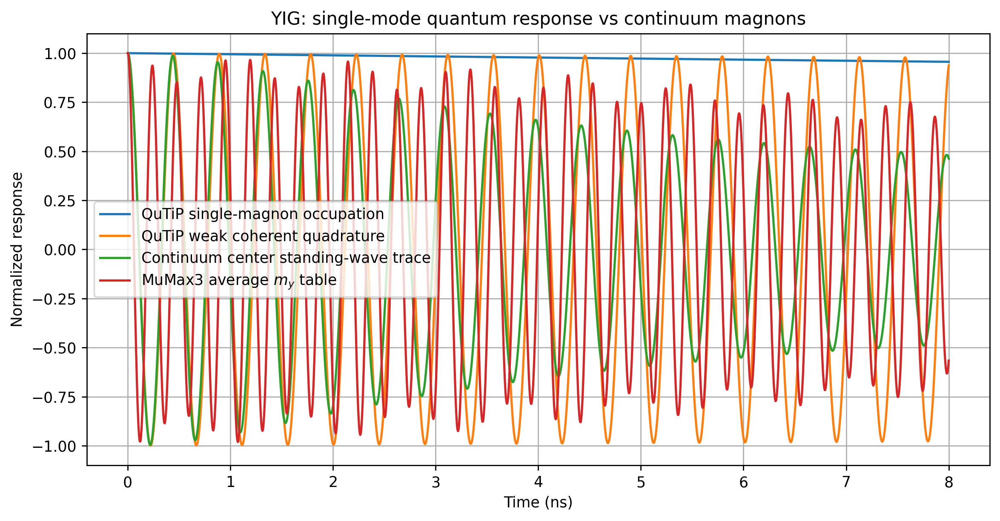

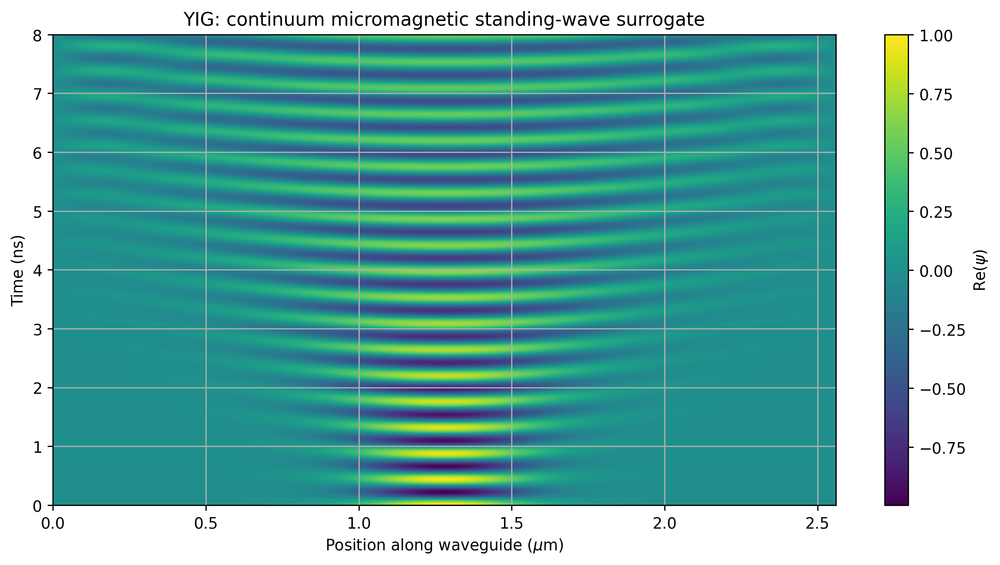

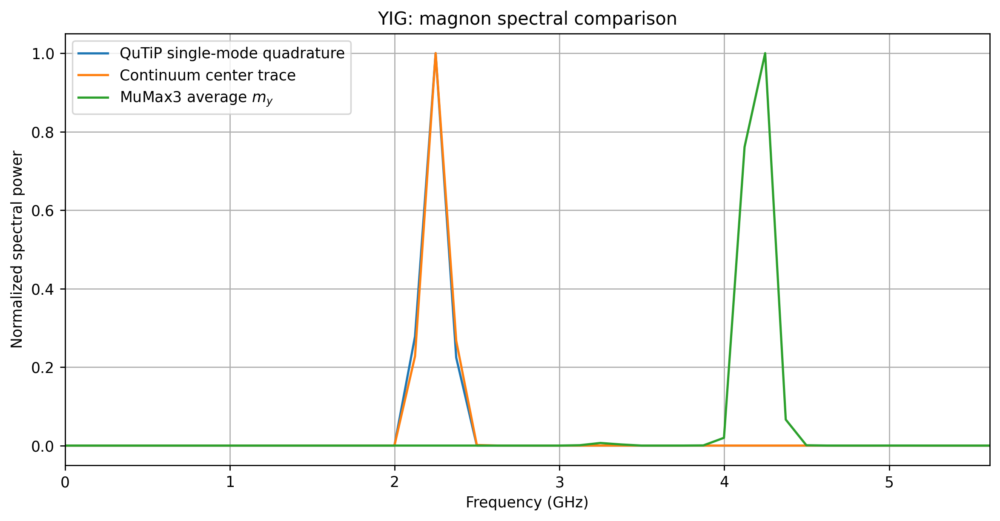


=== CoFeB case ===

Running MuMax3 table check for CoFeB
Script: /content/ew_magnon_demo/mumax_runs/cofeb.mx3


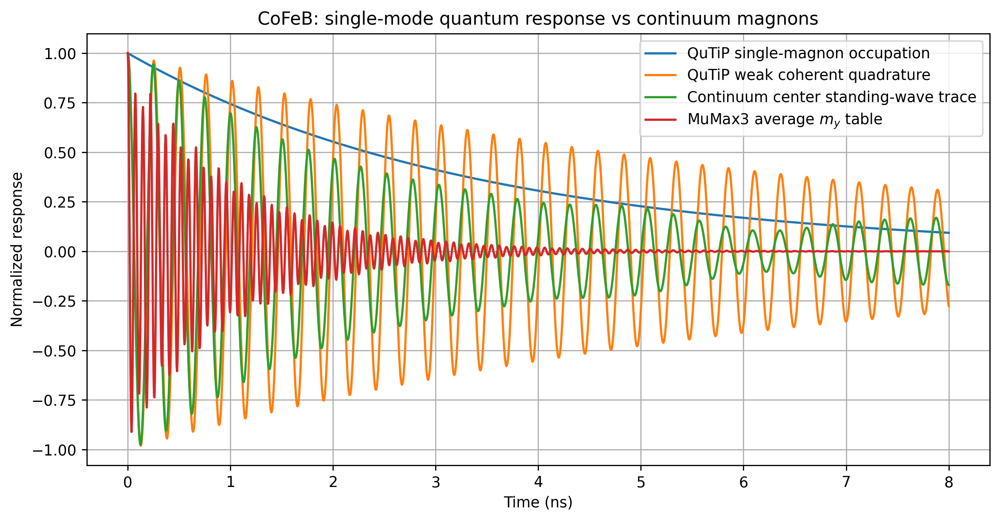

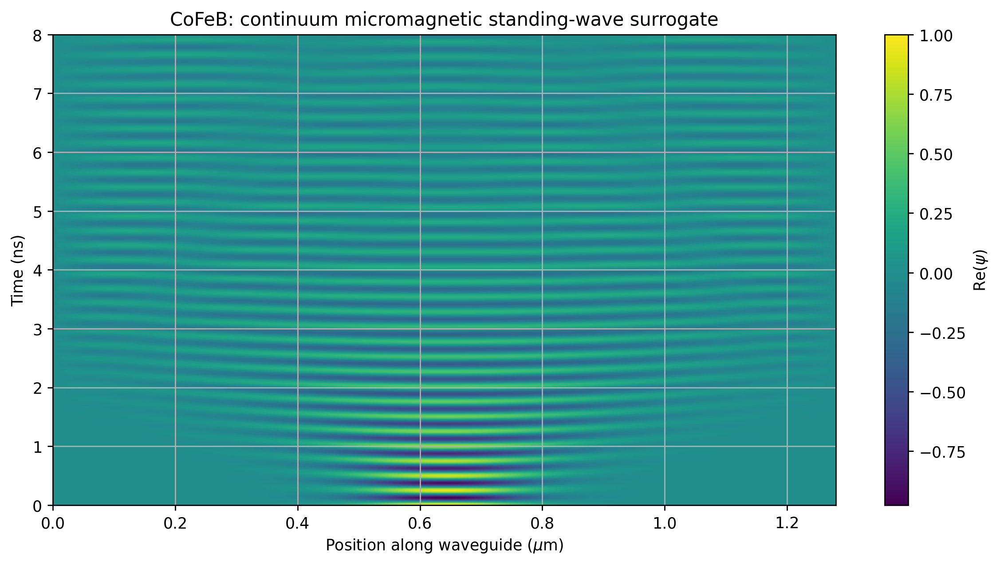

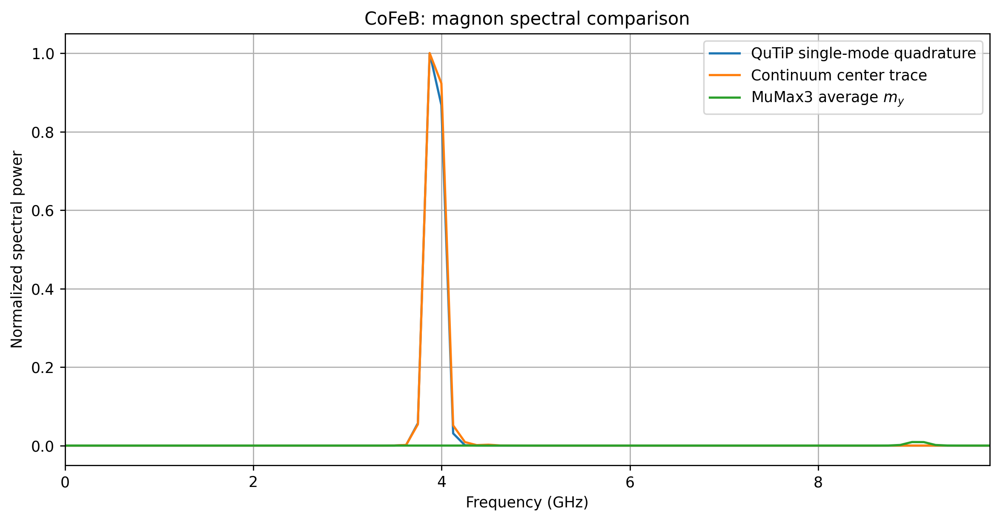

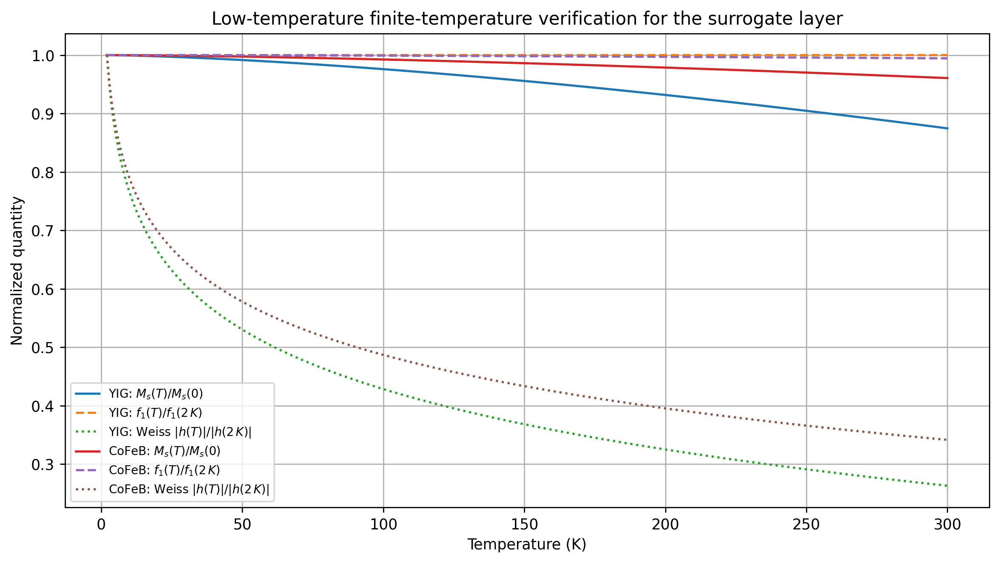


Numerical summary
material  Ms0_A_per_m  Aex0_J_per_m  alpha0  bias_T  qutip_nominal_freq_GHz  qutip_fft_peak_GHz  continuum_fft_peak_GHz  mumax_fft_peak_GHz  Ms_2K_over_Ms0  Ms_300K_over_Ms0  Weiss_h_2K  Weiss_h_300K
     YIG     140000.0  3.700000e-12  0.0002    0.08                2.244227            2.248750                2.248750            4.247877        0.999932          0.874527   10.284732      2.704022
   CoFeB    1200000.0  1.800000e-11  0.0060    0.12                3.928558            3.872847                3.872847           13.493257        0.999979          0.960564   11.442165      3.906308


In [7]:
#@title Quantum Magnon + Continuum Micromagnetic Magnon Demo for YIG and CoFeB
"""Compare QuTiP single-magnon dynamics with continuum magnon dynamics.

The workflow demonstrates four cases:
1. YIG single-magnon QuTiP reference.
2. YIG continuum micromagnetic magnon surrogate, with optional MuMax3 table run.
3. CoFeB single-magnon QuTiP reference.
4. CoFeB continuum micromagnetic magnon surrogate, with optional MuMax3 table run.

A final temperature-dependence plot checks the low-temperature finite-temperature
parameter flow used by the Ehrenfest-Weiss surrogate layer.
"""

import math
import os
import re
import shutil
import subprocess
import warnings
from dataclasses import dataclass
from pathlib import Path
from typing import Any, Final

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qutip as qt
import scipy.signal as sig


# =============================================================================
# CONTROL KNOBS
# =============================================================================

MPL_DPI: Final[int] = 250
USE_CUPY_IF_AVAILABLE: Final[bool] = True
RUN_MUMAX3_TABLE_CHECK: Final[bool] = True
USE_MUMAX3_WHEN_AVAILABLE: Final[bool] = True
FALL_BACK_TO_MODAL_CONTINUUM: Final[bool] = True

WORK_DIR: Final[Path] = Path("/content/ew_magnon_demo")
MUMAX_RUN_DIR: Final[Path] = WORK_DIR / "mumax_runs"

TIME_END_NS: Final[float] = 8.0
TIME_POINTS: Final[int] = 1800
TEMPERATURE_MIN_K: Final[float] = 2.0
TEMPERATURE_MAX_K: Final[float] = 300.0
TEMPERATURE_POINTS: Final[int] = 360

MAX_FOCK_LEVELS: Final[int] = 8
WEAK_COHERENT_ALPHA: Final[float] = 0.25
MIN_DAMPING_RATE_RAD_PER_S: Final[float] = 2.0e6

CONTINUUM_MODE_COUNT: Final[int] = 72
CONTINUUM_SPACE_POINTS: Final[int] = 512
INITIAL_PACKET_WIDTH_FRACTION: Final[float] = 0.075
INITIAL_PACKET_CENTER_FRACTION: Final[float] = 0.50
TEMPERATURE_EXCHANGE_SCALING_POWER: Final[float] = 2.0

MUMAX_TABLE_DT_PS: Final[float] = 4.0
MUMAX_INITIAL_TILT: Final[float] = 0.020
MUMAX_TIMEOUT_S: Final[int] = 180

MU0: Final[float] = 4.0e-7 * math.pi
GAMMA_RAD_PER_T_S: Final[float] = 1.760_859_630e11


# =============================================================================
# BACKEND SETUP
# =============================================================================

mpl.rcParams["figure.dpi"] = MPL_DPI
mpl.rcParams["savefig.dpi"] = MPL_DPI
mpl.rcParams["font.sans-serif"] = ["Tahoma", "DejaVu Sans"]
mpl.rcParams["axes.grid"] = True

try:
    if USE_CUPY_IF_AVAILABLE:
        import cupy as cp

        _device_count = cp.cuda.runtime.getDeviceCount()
        if _device_count > 0:
            XP = cp
            USING_CUPY = True
        else:
            XP = np
            USING_CUPY = False
    else:
        XP = np
        USING_CUPY = False
except Exception as backend_error:
    XP = np
    USING_CUPY = False
    print(f"CuPy backend unavailable. Falling back to NumPy. Reason: {backend_error}")

print(f"Array backend: {'CuPy GPU' if USING_CUPY else 'NumPy CPU'}")


# =============================================================================
# DATA STRUCTURES
# =============================================================================

@dataclass(frozen=True)
class MaterialCase:
    """Material and geometry settings for one magnon comparison case."""

    name: str
    symbol: str
    msat_0_a_per_m: float
    aex_0_j_per_m: float
    alpha_0: float
    bias_field_t: float
    curie_temp_k: float
    temp_strength: float
    length_m: float
    width_m: float
    thickness_m: float
    mumax_nx: int
    mumax_ny: int
    mumax_nz: int
    anisotropy_field_t: float = 0.0


MATERIALS: Final[list[MaterialCase]] = [
    MaterialCase(
        name="YIG",
        symbol="yig",
        msat_0_a_per_m=1.40e5,
        aex_0_j_per_m=3.70e-12,
        alpha_0=2.0e-4,
        bias_field_t=0.080,
        curie_temp_k=560.0,
        temp_strength=0.32,
        length_m=2.56e-6,
        width_m=0.32e-6,
        thickness_m=20.0e-9,
        mumax_nx=256,
        mumax_ny=32,
        mumax_nz=1,
    ),
    MaterialCase(
        name="CoFeB",
        symbol="cofeb",
        msat_0_a_per_m=1.20e6,
        aex_0_j_per_m=18.0e-12,
        alpha_0=6.0e-3,
        bias_field_t=0.120,
        curie_temp_k=1000.0,
        temp_strength=0.24,
        length_m=1.28e-6,
        width_m=0.16e-6,
        thickness_m=2.0e-9,
        mumax_nx=256,
        mumax_ny=32,
        mumax_nz=1,
        anisotropy_field_t=0.020,
    ),
]


# =============================================================================
# NUMERICAL HELPERS
# =============================================================================

def to_numpy(array_like: Any) -> np.ndarray:
    """Convert a NumPy or CuPy array to a NumPy array."""
    if USING_CUPY and isinstance(array_like, cp.ndarray):
        return cp.asnumpy(array_like)
    return np.asarray(array_like)


def trapz_backend(y_values: Any, x_values: Any, axis: int = 0) -> Any:
    """Use backend-compatible trapezoidal integration."""
    if hasattr(XP, "trapezoid"):
        return XP.trapezoid(y_values, x_values, axis=axis)
    return XP.trapz(y_values, x_values, axis=axis)


def safe_normalize(values: np.ndarray, eps: float = 1.0e-15) -> np.ndarray:
    """Normalize an array by its maximum absolute value."""
    array = np.asarray(values, dtype=float)
    scale = max(float(np.max(np.abs(array))), eps)
    return array / scale


def spectrum_from_time(
    time_s: np.ndarray,
    signal_values: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, float]:
    """Compute a one-sided normalized spectrum and its peak frequency."""
    signal_array = np.asarray(signal_values, dtype=float)
    signal_array = sig.detrend(signal_array, type="constant")

    if signal_array.size < 8:
        return np.array([0.0]), np.array([0.0]), 0.0

    dt_s = float(np.mean(np.diff(time_s)))
    window = sig.windows.hann(signal_array.size, sym=False)
    fft_values = np.fft.rfft(signal_array * window)
    freq_hz = np.fft.rfftfreq(signal_array.size, d=dt_s)
    power = np.abs(fft_values) ** 2

    if power.size > 1:
        power[0] = 0.0

    power_norm = safe_normalize(power)

    valid = freq_hz > 0.05e9
    if np.any(valid):
        peak_index_local = int(np.argmax(power_norm[valid]))
        peak_freq_hz = float(freq_hz[valid][peak_index_local])
    else:
        peak_freq_hz = 0.0

    return freq_hz, power_norm, peak_freq_hz


def base_mode_frequency_hz(material: MaterialCase) -> float:
    """Return the approximate fundamental exchange spin-wave frequency."""
    k_1 = math.pi / material.length_m
    exchange_field_t = 2.0 * material.aex_0_j_per_m * k_1**2
    exchange_field_t /= material.msat_0_a_per_m
    total_field_t = (
        material.bias_field_t
        + material.anisotropy_field_t
        + exchange_field_t
    )
    omega_rad_per_s = GAMMA_RAD_PER_T_S * total_field_t
    return omega_rad_per_s / (2.0 * math.pi)


def material_temperature_curve(
    material: MaterialCase,
    temperature_k: np.ndarray,
) -> dict[str, np.ndarray]:
    """Compute finite-temperature material and Weiss-closure diagnostics."""
    theta = np.clip(temperature_k / material.curie_temp_k, 0.0, 0.999)
    ms_reduced = 1.0 - material.temp_strength * theta**1.5
    ms_reduced = np.clip(ms_reduced, 1.0e-4, 0.999_999)

    ms_t = material.msat_0_a_per_m * ms_reduced
    aex_t = material.aex_0_j_per_m * ms_reduced**TEMPERATURE_EXCHANGE_SCALING_POWER
    alpha_t = material.alpha_0 * (1.0 + 0.65 * theta**2)

    k_1 = math.pi / material.length_m
    exchange_field_t = 2.0 * aex_t * k_1**2 / ms_t
    anisotropy_field_t = material.anisotropy_field_t * ms_reduced
    total_field_t = material.bias_field_t + anisotropy_field_t + exchange_field_t
    freq_hz = GAMMA_RAD_PER_T_S * total_field_t / (2.0 * math.pi)

    weiss_h_norm = 2.0 * np.arctanh(ms_reduced)

    return {
        "temperature_k": temperature_k,
        "ms_reduced": ms_reduced,
        "ms_t": ms_t,
        "aex_t": aex_t,
        "alpha_t": alpha_t,
        "freq_hz": freq_hz,
        "freq_reduced": freq_hz / max(float(freq_hz[0]), 1.0e-30),
        "weiss_h_norm": weiss_h_norm,
        "weiss_h_reduced": weiss_h_norm / max(float(weiss_h_norm[0]), 1.0e-30),
    }


# =============================================================================
# QUTIP SINGLE-MAGNON REFERENCE
# =============================================================================

def simulate_single_magnon_qutip(
    material: MaterialCase,
    time_s: np.ndarray,
) -> dict[str, np.ndarray | float]:
    """Simulate a damped single-magnon oscillator with QuTiP."""
    omega_rad_per_s = 2.0 * math.pi * base_mode_frequency_hz(material)
    kappa_rad_per_s = max(
        2.0 * material.alpha_0 * omega_rad_per_s,
        MIN_DAMPING_RATE_RAD_PER_S,
    )

    a_op = qt.destroy(MAX_FOCK_LEVELS)
    n_op = a_op.dag() * a_op
    hamiltonian = omega_rad_per_s * n_op
    c_ops = [math.sqrt(kappa_rad_per_s) * a_op]

    single_magnon_state = qt.basis(MAX_FOCK_LEVELS, 1)
    single_result = qt.mesolve(
        hamiltonian,
        single_magnon_state,
        time_s,
        c_ops,
        e_ops=[n_op],
    )

    coherent_state = qt.coherent(MAX_FOCK_LEVELS, WEAK_COHERENT_ALPHA)
    x_quadrature = a_op + a_op.dag()
    y_quadrature = -1j * (a_op - a_op.dag())
    coherent_result = qt.mesolve(
        hamiltonian,
        coherent_state,
        time_s,
        c_ops,
        e_ops=[n_op, x_quadrature, y_quadrature],
    )

    occupation = np.real(np.asarray(single_result.expect[0], dtype=float))
    coherent_n = np.real(np.asarray(coherent_result.expect[0], dtype=float))
    coherent_x = np.real(np.asarray(coherent_result.expect[1], dtype=float))
    coherent_y = np.real(np.asarray(coherent_result.expect[2], dtype=float))

    return {
        "time_s": time_s,
        "occupation": occupation,
        "coherent_n": coherent_n,
        "coherent_x": coherent_x,
        "coherent_y": coherent_y,
        "omega_rad_per_s": omega_rad_per_s,
        "frequency_hz": omega_rad_per_s / (2.0 * math.pi),
        "kappa_rad_per_s": kappa_rad_per_s,
    }


# =============================================================================
# CONTINUUM MODAL MICROMAGNETIC MAGNON SURROGATE
# =============================================================================

def simulate_modal_continuum(
    material: MaterialCase,
    time_s: np.ndarray,
) -> dict[str, np.ndarray | float]:
    """Simulate a linearized 1D continuum spin-wave packet on a GPU array."""
    x = XP.linspace(0.0, material.length_m, CONTINUUM_SPACE_POINTS)
    t = XP.asarray(time_s, dtype=XP.float64)

    mode_indices = XP.arange(1, CONTINUUM_MODE_COUNT + 1, dtype=XP.float64)
    k_modes = math.pi * mode_indices / material.length_m

    x0 = INITIAL_PACKET_CENTER_FRACTION * material.length_m
    sigma_x = INITIAL_PACKET_WIDTH_FRACTION * material.length_m
    initial_packet = XP.exp(-0.5 * ((x - x0) / sigma_x) ** 2)

    basis = XP.sin(x[:, None] * k_modes[None, :])
    coefficients = (2.0 / material.length_m) * trapz_backend(
        initial_packet[:, None] * basis,
        x,
        axis=0,
    )

    exchange_field_t = 2.0 * material.aex_0_j_per_m * k_modes**2
    exchange_field_t /= material.msat_0_a_per_m

    total_field_t = (
        material.bias_field_t
        + material.anisotropy_field_t
        + exchange_field_t
    )
    omega_modes = GAMMA_RAD_PER_T_S * total_field_t

    decay_phase = XP.exp(
        -material.alpha_0 * omega_modes[:, None] * t[None, :]
        - 1j * omega_modes[:, None] * t[None, :]
    )

    mode_time = coefficients[:, None] * decay_phase
    psi_xt = basis @ mode_time

    max_abs = XP.max(XP.abs(psi_xt))
    psi_xt = psi_xt / XP.maximum(max_abs, 1.0e-30)

    center_index = CONTINUUM_SPACE_POINTS // 2
    center_trace = XP.real(psi_xt[center_index, :])
    mean_trace = XP.real(XP.mean(psi_xt, axis=0))

    return {
        "x_m": to_numpy(x),
        "time_s": np.asarray(time_s),
        "psi_real": to_numpy(XP.real(psi_xt)),
        "psi_abs": to_numpy(XP.abs(psi_xt)),
        "center_trace": to_numpy(center_trace),
        "mean_trace": to_numpy(mean_trace),
        "mode_freq_hz": to_numpy(omega_modes / (2.0 * math.pi)),
    }


# =============================================================================
# OPTIONAL MUMAX3 TABLE CHECK
# =============================================================================

def make_safe_name(text: str) -> str:
    """Create a safe file stem from a label."""
    return re.sub(r"[^a-zA-Z0-9_]+", "_", text.lower()).strip("_")


def build_mumax_script(material: MaterialCase, time_end_s: float) -> str:
    """Build a minimal MuMax3 script that records average magnetization."""
    dx_m = material.length_m / material.mumax_nx
    dy_m = material.width_m / material.mumax_ny
    dz_m = material.thickness_m / material.mumax_nz
    table_dt_s = MUMAX_TABLE_DT_PS * 1.0e-12

    return f"""
// Generated by the Ehrenfest-Weiss magnon comparison notebook.
SetGridSize({material.mumax_nx}, {material.mumax_ny}, {material.mumax_nz})
SetCellSize({dx_m:.16e}, {dy_m:.16e}, {dz_m:.16e})

Msat = {material.msat_0_a_per_m:.16e}
Aex = {material.aex_0_j_per_m:.16e}
alpha = {material.alpha_0:.16e}

B_ext = vector({material.bias_field_t:.16e}, 0, 0)
m = uniform(1, {MUMAX_INITIAL_TILT:.16e}, 0)

TableAdd(m)
TableAutoSave({table_dt_s:.16e})

Run({time_end_s:.16e})
TableSave()
"""


def read_mumax_table(table_path: Path) -> pd.DataFrame:
    """Read a MuMax3 table file into a DataFrame."""
    data = np.loadtxt(table_path, comments="#")
    if data.ndim == 1:
        data = data[None, :]

    column_count = data.shape[1]
    base_columns = ["time_s", "mx", "my", "mz"]
    if column_count <= len(base_columns):
        columns = base_columns[:column_count]
    else:
        extra_columns = [f"extra_{idx}" for idx in range(column_count - 4)]
        columns = base_columns + extra_columns

    return pd.DataFrame(data, columns=columns)


def run_mumax_table_case(
    material: MaterialCase,
    time_end_s: float,
) -> pd.DataFrame | None:
    """Run a small MuMax3 table simulation when the executable is available."""
    if (RUN_MUMAX3_TABLE_CHECK and USE_MUMAX3_WHEN_AVAILABLE) is False:
        return None

    mumax_path = shutil.which("mumax3")
    if mumax_path is None:
        print(f"MuMax3 executable unavailable for {material.name}.")
        return None

    MUMAX_RUN_DIR.mkdir(parents=True, exist_ok=True)

    stem = make_safe_name(material.name)
    script_path = MUMAX_RUN_DIR / f"{stem}.mx3"
    output_dir = MUMAX_RUN_DIR / f"{stem}.out"

    if output_dir.exists():
        shutil.rmtree(output_dir)

    script_path.write_text(build_mumax_script(material, time_end_s))

    print(f"\nRunning MuMax3 table check for {material.name}")
    print(f"Script: {script_path}")

    try:
        subprocess.run(
            [mumax_path, str(script_path)],
            check=True,
            timeout=MUMAX_TIMEOUT_S,
            cwd=str(MUMAX_RUN_DIR),
        )
    except subprocess.TimeoutExpired:
        print(f"MuMax3 timed out for {material.name}. Modal surrogate will be used.")
        return None
    except subprocess.CalledProcessError as error:
        print(f"MuMax3 failed for {material.name} with code {error.returncode}.")
        return None

    table_path = output_dir / "table.txt"
    if table_path.exists() is False:
        print(f"MuMax3 table file absent for {material.name}: {table_path}")
        return None

    try:
        return read_mumax_table(table_path)
    except Exception as read_error:
        print(f"MuMax3 table parsing failed for {material.name}: {read_error}")
        return None


# =============================================================================
# PLOTTING
# =============================================================================

def plot_time_comparison(
    material: MaterialCase,
    quantum_data: dict[str, np.ndarray | float],
    continuum_data: dict[str, np.ndarray | float],
    mumax_table: pd.DataFrame | None,
) -> None:
    """Render a time-domain comparison for one material."""
    time_ns = np.asarray(quantum_data["time_s"]) * 1.0e9
    q_occ = safe_normalize(np.asarray(quantum_data["occupation"]))
    q_quad = safe_normalize(np.asarray(quantum_data["coherent_x"]))
    cont_trace = safe_normalize(np.asarray(continuum_data["center_trace"]))

    plt.figure(figsize=(9.5, 5.0))
    plt.plot(time_ns, q_occ, label="QuTiP single-magnon occupation")
    plt.plot(time_ns, q_quad, label="QuTiP weak coherent quadrature")
    plt.plot(time_ns, cont_trace, label="Continuum center standing-wave trace")

    if mumax_table is not None and {"time_s", "my"}.issubset(mumax_table.columns):
        mumax_time_ns = mumax_table["time_s"].to_numpy() * 1.0e9
        mumax_my = safe_normalize(mumax_table["my"].to_numpy())
        plt.plot(mumax_time_ns, mumax_my, label="MuMax3 average $m_y$ table")

    plt.xlabel("Time (ns)")
    plt.ylabel("Normalized response")
    plt.title(f"{material.name}: single-mode quantum response vs continuum magnons")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


def plot_continuum_heatmap(
    material: MaterialCase,
    continuum_data: dict[str, np.ndarray | float],
) -> None:
    """Render the continuum standing-wave heatmap."""
    x_um = np.asarray(continuum_data["x_m"]) * 1.0e6
    time_ns = np.asarray(continuum_data["time_s"]) * 1.0e9
    psi_real = np.asarray(continuum_data["psi_real"]).T

    plt.figure(figsize=(9.5, 5.2))
    extent = [float(x_um[0]), float(x_um[-1]), float(time_ns[0]), float(time_ns[-1])]
    image = plt.imshow(
        psi_real,
        extent=extent,
        origin="lower",
        aspect="auto",
        interpolation="nearest",
    )
    plt.colorbar(image, label=r"Re$(\psi)$")
    plt.xlabel("Position along waveguide ($\\mu$m)")
    plt.ylabel("Time (ns)")
    plt.title(f"{material.name}: continuum micromagnetic standing-wave surrogate")
    plt.tight_layout()
    plt.show()


def plot_spectrum_comparison(
    material: MaterialCase,
    quantum_data: dict[str, np.ndarray | float],
    continuum_data: dict[str, np.ndarray | float],
    mumax_table: pd.DataFrame | None,
) -> dict[str, float]:
    """Render spectra and return peak-frequency diagnostics."""
    time_s = np.asarray(quantum_data["time_s"])
    q_freq_hz, q_power, q_peak_hz = spectrum_from_time(
        time_s,
        np.asarray(quantum_data["coherent_x"]),
    )
    c_freq_hz, c_power, c_peak_hz = spectrum_from_time(
        time_s,
        np.asarray(continuum_data["center_trace"]),
    )

    mumax_peak_hz = math.nan
    mumax_freq_hz = np.array([])
    mumax_power = np.array([])

    if mumax_table is not None and {"time_s", "my"}.issubset(mumax_table.columns):
        mumax_freq_hz, mumax_power, mumax_peak_hz = spectrum_from_time(
            mumax_table["time_s"].to_numpy(),
            mumax_table["my"].to_numpy(),
        )

    plt.figure(figsize=(9.5, 5.0))
    plt.plot(q_freq_hz * 1.0e-9, q_power, label="QuTiP single-mode quadrature")
    plt.plot(c_freq_hz * 1.0e-9, c_power, label="Continuum center trace")

    if mumax_freq_hz.size > 0:
        plt.plot(mumax_freq_hz * 1.0e-9, mumax_power, label="MuMax3 average $m_y$")

    upper_ghz = max(
        5.0,
        2.5 * float(quantum_data["frequency_hz"]) * 1.0e-9,
    )
    plt.xlim(0.0, min(upper_ghz, 80.0))
    plt.xlabel("Frequency (GHz)")
    plt.ylabel("Normalized spectral power")
    plt.title(f"{material.name}: magnon spectral comparison")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    return {
        "qutip_peak_ghz": q_peak_hz * 1.0e-9,
        "continuum_peak_ghz": c_peak_hz * 1.0e-9,
        "mumax_peak_ghz": mumax_peak_hz * 1.0e-9
        if np.isfinite(mumax_peak_hz)
        else math.nan,
    }


def plot_temperature_dependence(
    curves: dict[str, dict[str, np.ndarray]],
) -> None:
    """Render a finite-temperature verification plot for all materials."""
    plt.figure(figsize=(9.5, 5.4))

    for material_name, curve in curves.items():
        temperature_k = curve["temperature_k"]
        plt.plot(
            temperature_k,
            curve["ms_reduced"],
            label=f"{material_name}: $M_s(T)/M_s(0)$",
        )
        plt.plot(
            temperature_k,
            curve["freq_reduced"],
            linestyle="--",
            label=f"{material_name}: $f_1(T)/f_1(2\\,K)$",
        )
        plt.plot(
            temperature_k,
            curve["weiss_h_reduced"],
            linestyle=":",
            label=f"{material_name}: Weiss $|h(T)|/|h(2\\,K)|$",
        )

    plt.xlabel("Temperature (K)")
    plt.ylabel("Normalized quantity")
    plt.title("Low-temperature finite-temperature verification for the surrogate layer")
    plt.legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()


# =============================================================================
# MAIN WORKFLOW
# =============================================================================

def run_material_case(
    material: MaterialCase,
    time_s: np.ndarray,
) -> dict[str, Any]:
    """Run one material through the quantum and continuum comparison workflow."""
    print(f"\n=== {material.name} case ===")

    quantum_data = simulate_single_magnon_qutip(material, time_s)
    continuum_data = simulate_modal_continuum(material, time_s)

    mumax_table = None
    if RUN_MUMAX3_TABLE_CHECK:
        mumax_table = run_mumax_table_case(material, float(time_s[-1]))

    plot_time_comparison(material, quantum_data, continuum_data, mumax_table)
    plot_continuum_heatmap(material, continuum_data)
    spectral_summary = plot_spectrum_comparison(
        material,
        quantum_data,
        continuum_data,
        mumax_table,
    )

    return {
        "material": material,
        "quantum": quantum_data,
        "continuum": continuum_data,
        "mumax_table": mumax_table,
        "spectral_summary": spectral_summary,
    }


def build_summary_table(results: list[dict[str, Any]]) -> pd.DataFrame:
    """Build a compact numerical summary table."""
    rows = []

    for result in results:
        material = result["material"]
        quantum_data = result["quantum"]
        spectral_summary = result["spectral_summary"]

        temp_probe = np.array([2.0, 300.0])
        temp_curve = material_temperature_curve(material, temp_probe)

        rows.append(
            {
                "material": material.name,
                "Ms0_A_per_m": material.msat_0_a_per_m,
                "Aex0_J_per_m": material.aex_0_j_per_m,
                "alpha0": material.alpha_0,
                "bias_T": material.bias_field_t,
                "qutip_nominal_freq_GHz": float(quantum_data["frequency_hz"]) * 1.0e-9,
                "qutip_fft_peak_GHz": spectral_summary["qutip_peak_ghz"],
                "continuum_fft_peak_GHz": spectral_summary["continuum_peak_ghz"],
                "mumax_fft_peak_GHz": spectral_summary["mumax_peak_ghz"],
                "Ms_2K_over_Ms0": temp_curve["ms_reduced"][0],
                "Ms_300K_over_Ms0": temp_curve["ms_reduced"][1],
                "Weiss_h_2K": temp_curve["weiss_h_norm"][0],
                "Weiss_h_300K": temp_curve["weiss_h_norm"][1],
            }
        )

    return pd.DataFrame(rows)


def main() -> list[dict[str, Any]]:
    """Execute the complete magnon comparison demonstration."""
    warnings.filterwarnings("ignore", category=FutureWarning)

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    MUMAX_RUN_DIR.mkdir(parents=True, exist_ok=True)

    time_s = np.linspace(0.0, TIME_END_NS * 1.0e-9, TIME_POINTS)

    print("Backend status")
    print(f"  Array backend       : {'CuPy GPU' if USING_CUPY else 'NumPy CPU'}")
    print(f"  MuMax3 available    : {shutil.which('mumax3') is not None}")
    print(f"  Work directory      : {WORK_DIR}")

    results = []
    for material in MATERIALS:
        results.append(run_material_case(material, time_s))

    temperature_k = np.linspace(
        TEMPERATURE_MIN_K,
        TEMPERATURE_MAX_K,
        TEMPERATURE_POINTS,
    )
    temperature_curves = {
        material.name: material_temperature_curve(material, temperature_k)
        for material in MATERIALS
    }
    plot_temperature_dependence(temperature_curves)

    summary = build_summary_table(results)
    print("\nNumerical summary")
    with pd.option_context("display.max_columns", None, "display.width", 180):
        print(summary.to_string(index=False))

    return results


if __name__ == "__main__":
    results = main()

Running stronger diagnostic plots.
Material cases: 2

=== Diagnostics for YIG ===


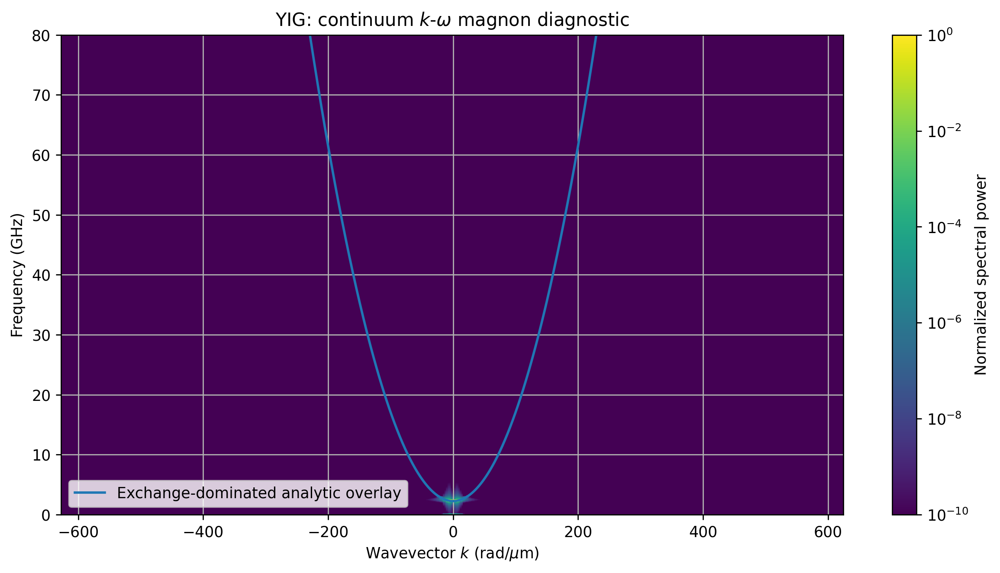

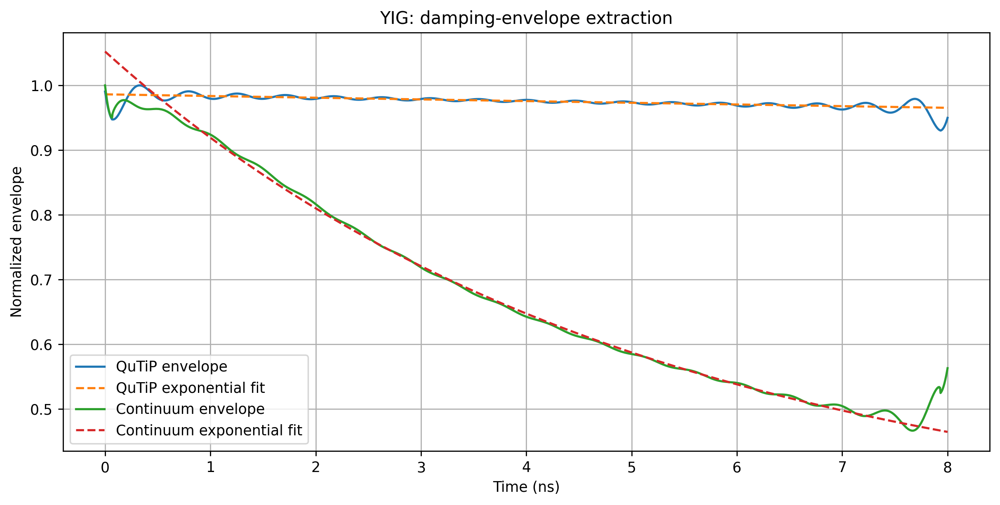

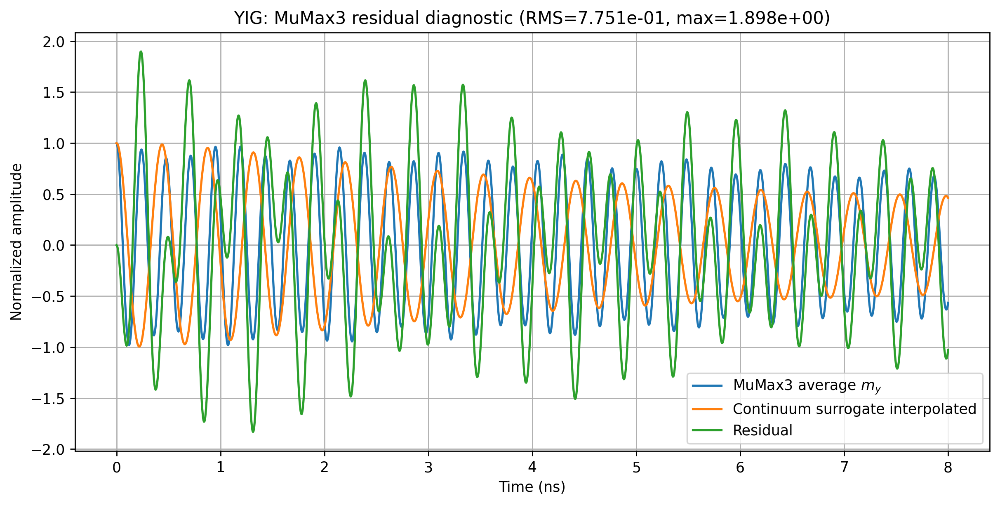

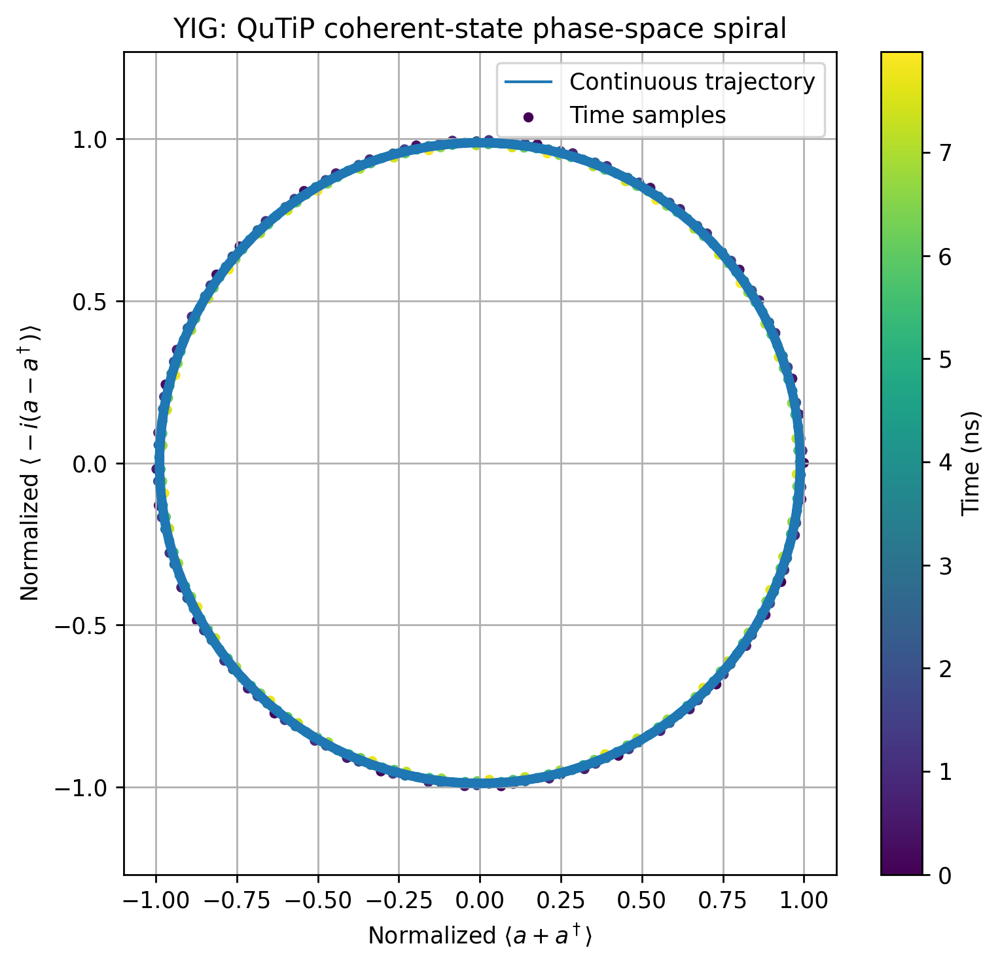


=== Diagnostics for CoFeB ===


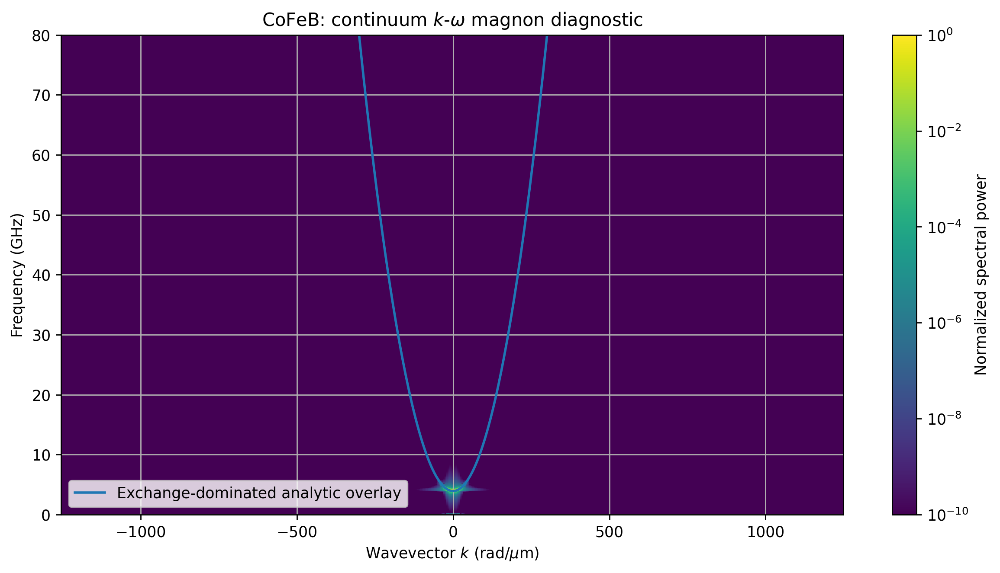

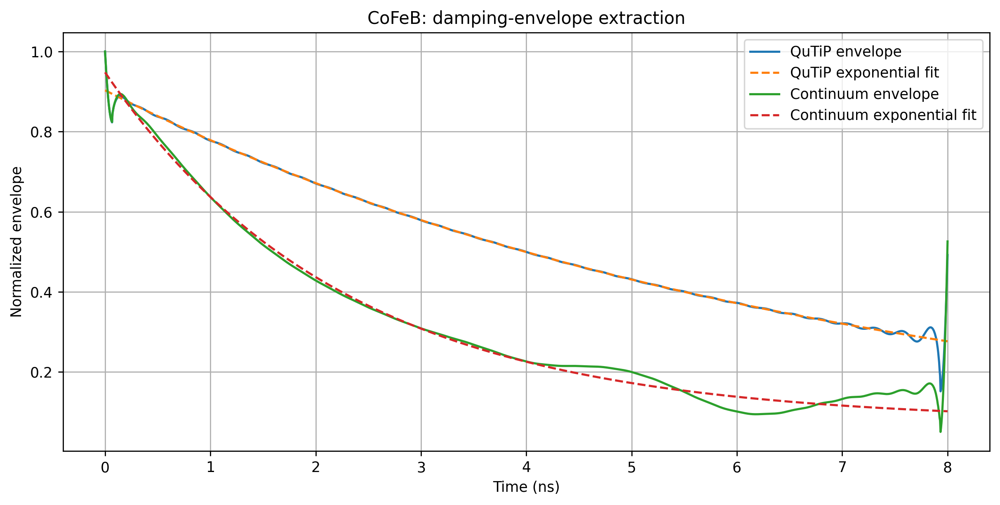

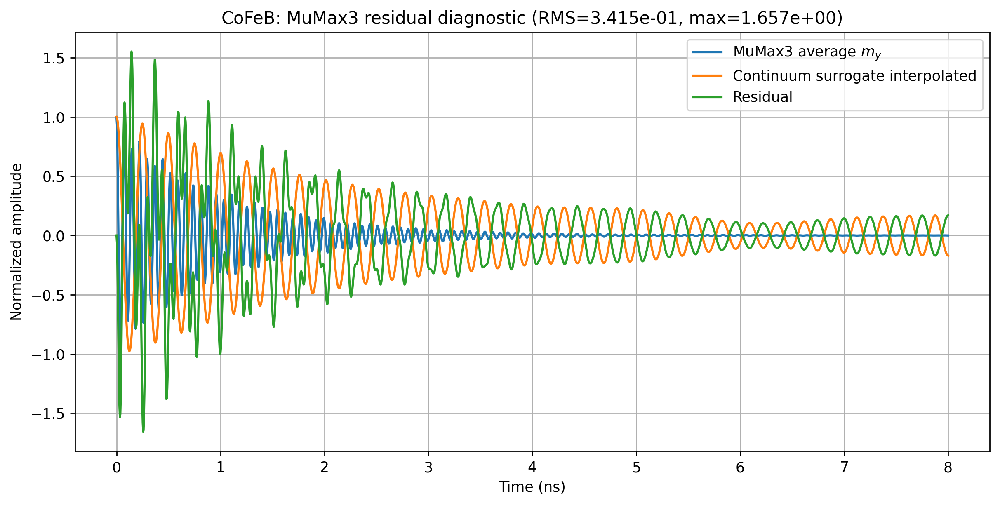

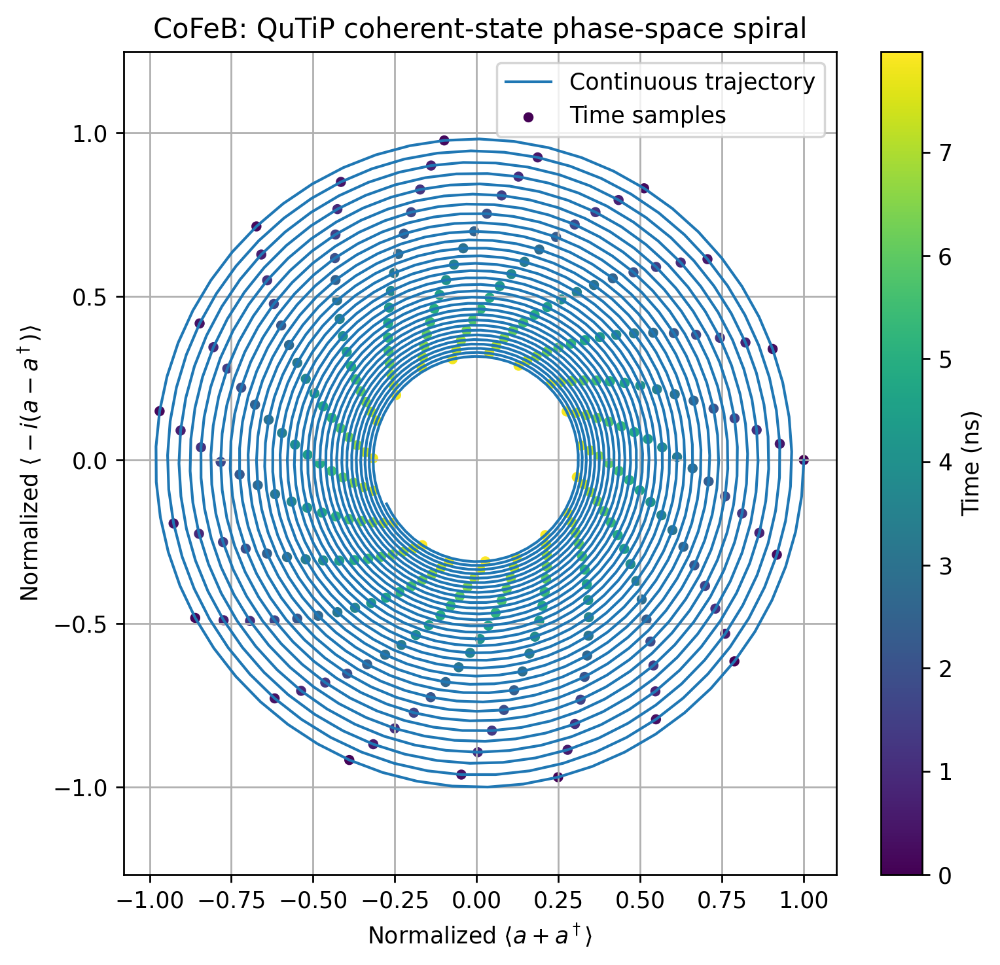

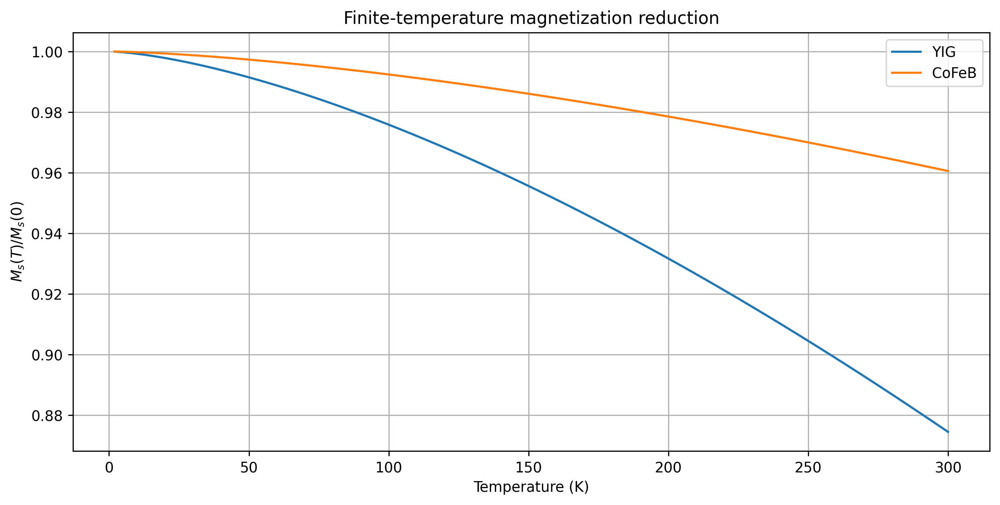

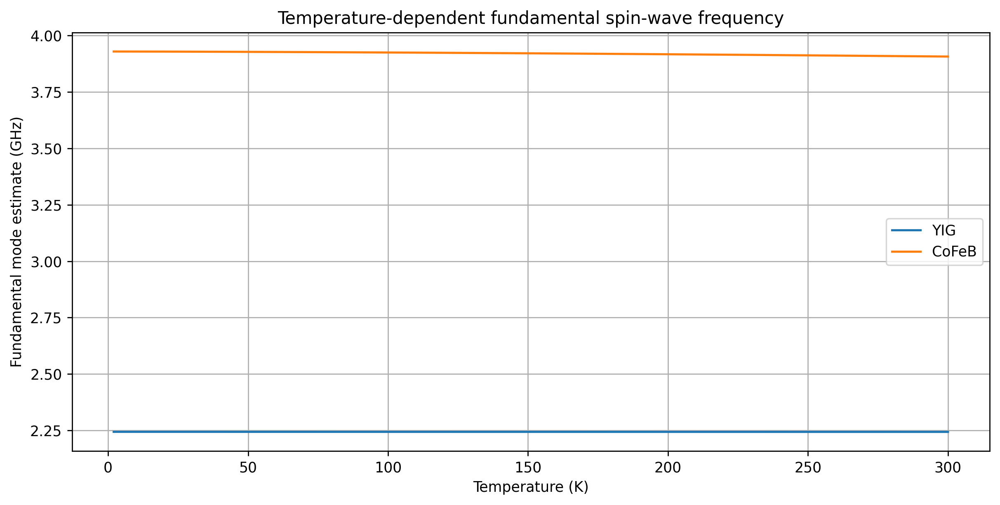

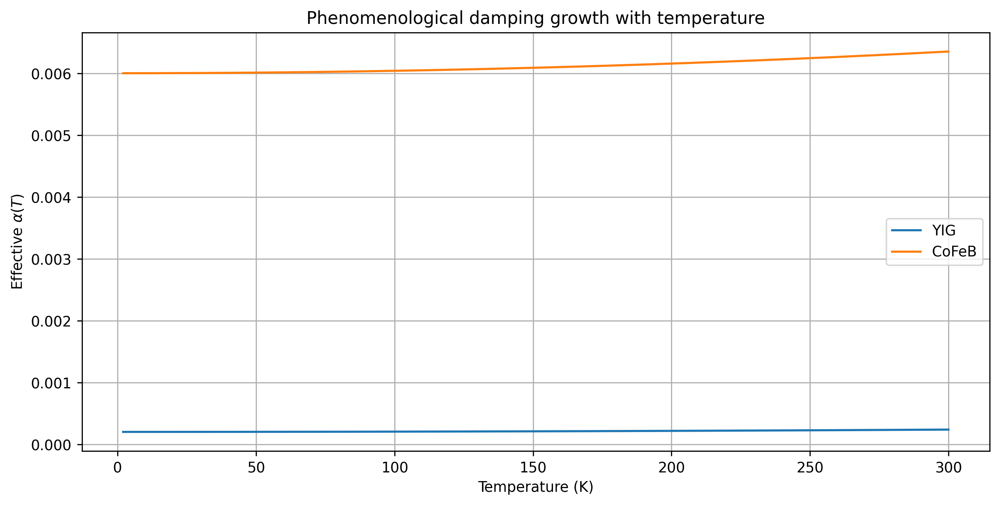

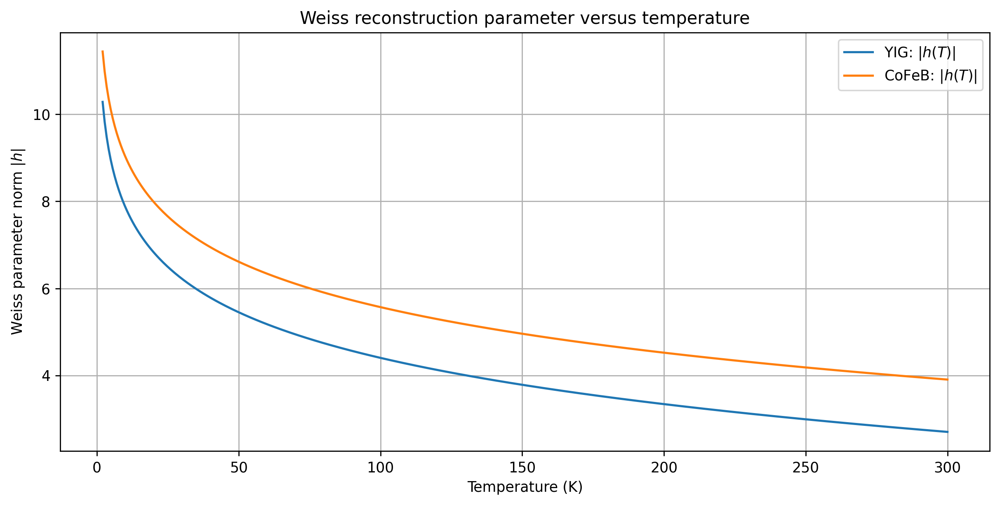

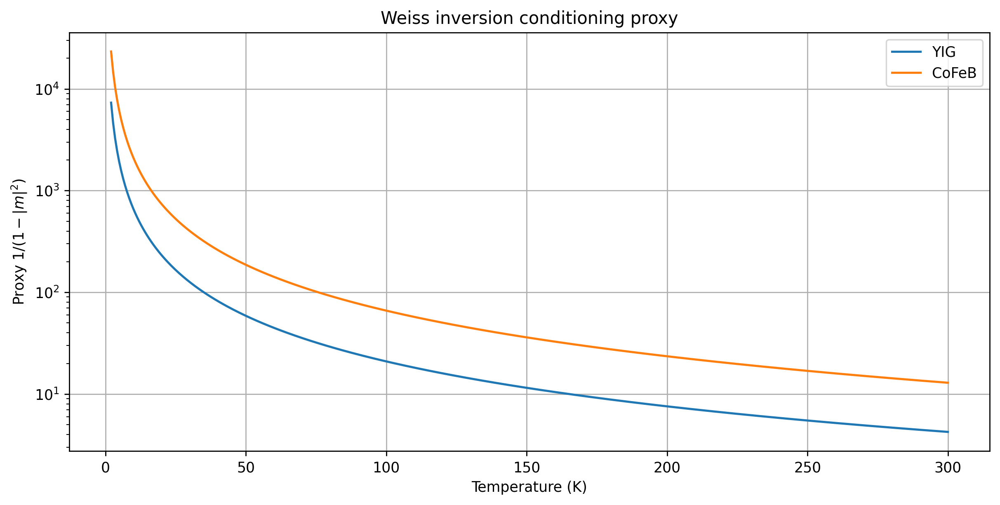


Damping-fit summary
material                    source  gamma_per_ns     tau_ns  alpha_eff  reference_freq_GHz   fit_r2
     YIG QuTiP coherent quadrature      0.002669 374.720472   0.000189            2.244227 0.817170
     YIG    Continuum center trace      0.198842   5.029120   0.014101            2.244227 0.998996
   CoFeB QuTiP coherent quadrature      0.148582   6.730285   0.006019            3.928558 0.999956
   CoFeB    Continuum center trace      0.441314   2.265958   0.017879            3.928558 0.991469

MuMax3 residual summary
material  mumax_residual_rms  mumax_residual_max_abs
     YIG            0.775103                1.898146
   CoFeB            0.341506                1.657270


In [8]:
#@title Additional Diagnostics for the Ehrenfest-Weiss Magnon Comparison
"""Add validation diagnostics to the YIG and CoFeB magnon comparison.

This cell adds the following diagnostics:
1. k-omega dispersion heatmaps from the continuum field psi(x, t).
2. Exponential damping-envelope fits for QuTiP and continuum traces.
3. MuMax3-minus-surrogate residual plots when MuMax3 tables are present.
4. QuTiP phase-space trajectories from coherent-state quadratures.
5. Separated temperature plots for magnetization, frequency, and damping.
6. Weiss inversion and closure-conditioning proxies.
"""

import math
from collections.abc import Callable
from dataclasses import dataclass
from typing import Any, Final

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.optimize as opt
import scipy.signal as signal
from matplotlib.colors import LogNorm


# =============================================================================
# CONTROL KNOBS
# =============================================================================

MPL_DPI: Final[int] = 250

K_OMEGA_MAX_GHZ: Final[float] = 80.0
K_OMEGA_MIN_POWER_FLOOR: Final[float] = 1.0e-10
K_OMEGA_OVERLAY_POINTS: Final[int] = 900

DAMPING_FIT_START_FRACTION: Final[float] = 0.06
DAMPING_FIT_STOP_FRACTION: Final[float] = 0.92
DAMPING_ENVELOPE_SMOOTHING_POINTS: Final[int] = 31
DAMPING_MIN_ENVELOPE: Final[float] = 1.0e-5

PHASE_TRAJECTORY_STRIDE: Final[int] = 6

TEMPERATURE_MIN_K: Final[float] = 2.0
TEMPERATURE_MAX_K: Final[float] = 300.0
TEMPERATURE_POINTS: Final[int] = 420
TEMPERATURE_EXCHANGE_SCALING_POWER: Final[float] = 2.0

MU0: Final[float] = 4.0e-7 * math.pi
GAMMA_RAD_PER_T_S: Final[float] = 1.760_859_630e11


# =============================================================================
# MATPLOTLIB CONFIGURATION
# =============================================================================

mpl.rcParams["figure.dpi"] = MPL_DPI
mpl.rcParams["savefig.dpi"] = MPL_DPI
mpl.rcParams["font.sans-serif"] = ["Tahoma", "DejaVu Sans"]
mpl.rcParams["axes.grid"] = True


# =============================================================================
# DATA STRUCTURES
# =============================================================================

@dataclass(frozen=True)
class DampingFit:
    """Container for an exponential envelope fit."""

    material: str
    source: str
    gamma_per_ns: float
    tau_ns: float
    alpha_eff: float
    reference_freq_ghz: float
    fit_r2: float


# =============================================================================
# BASIC HELPERS
# =============================================================================

def get_previous_results() -> list[dict[str, Any]]:
    """Load previous results or execute the previous main function once."""
    previous_results = globals().get("results")

    if previous_results is None:
        previous_main = globals().get("main")
        if callable(previous_main):
            print("Previous `results` variable absent, executing `main()` once.")
            previous_results = previous_main()
        else:
            raise RuntimeError(
                "Run the previous magnon comparison cell first so `results` exists."
            )

    if len(previous_results) == 0:
        raise RuntimeError("The `results` list is empty.")

    return previous_results


def as_float_array(values: Any) -> np.ndarray:
    """Convert an array-like object into a finite float array."""
    array = np.asarray(values, dtype=float)
    return np.nan_to_num(array, nan=0.0, posinf=0.0, neginf=0.0)


def normalize(values: Any, eps: float = 1.0e-15) -> np.ndarray:
    """Normalize an array by its largest absolute value."""
    array = as_float_array(values)
    scale = max(float(np.max(np.abs(array))), eps)
    return array / scale


def get_attr(obj: Any, name: str, default: Any = None) -> Any:
    """Read either an object attribute or dictionary entry."""
    if hasattr(obj, name):
        return getattr(obj, name)
    if isinstance(obj, dict):
        return obj.get(name, default)
    return default


def centered_time_ns(time_s: np.ndarray) -> np.ndarray:
    """Return time in ns shifted to begin at zero."""
    time_ns = as_float_array(time_s) * 1.0e9
    return time_ns - float(time_ns[0])


def safe_interp(
    x_new: np.ndarray,
    x_old: np.ndarray,
    y_old: np.ndarray,
) -> np.ndarray:
    """Interpolate y(x) onto x_new with bounded endpoints."""
    x_new = as_float_array(x_new)
    x_old = as_float_array(x_old)
    y_old = as_float_array(y_old)

    order = np.argsort(x_old)
    x_sorted = x_old[order]
    y_sorted = y_old[order]

    return np.interp(
        x_new,
        x_sorted,
        y_sorted,
        left=float(y_sorted[0]),
        right=float(y_sorted[-1]),
    )


def analytic_spin_wave_frequency_hz(
    material: Any,
    k_rad_per_m: np.ndarray,
) -> np.ndarray:
    """Compute the exchange-dominated spin-wave frequency estimate."""
    msat = float(get_attr(material, "msat_0_a_per_m"))
    aex = float(get_attr(material, "aex_0_j_per_m"))
    bias_field_t = float(get_attr(material, "bias_field_t"))
    anisotropy_field_t = float(get_attr(material, "anisotropy_field_t", 0.0))

    exchange_field_t = 2.0 * aex * k_rad_per_m**2 / msat
    total_field_t = bias_field_t + anisotropy_field_t + exchange_field_t
    return GAMMA_RAD_PER_T_S * total_field_t / (2.0 * math.pi)


def estimate_reference_frequency_ghz(result: dict[str, Any]) -> float:
    """Estimate a reference frequency from available result fields."""
    quantum = result["quantum"]
    frequency_hz = float(quantum.get("frequency_hz", 0.0))

    if frequency_hz <= 0.0:
        time_s = as_float_array(quantum["time_s"])
        trace = as_float_array(quantum["coherent_x"])
        frequency_hz = dominant_frequency_hz(time_s, trace)

    return frequency_hz * 1.0e-9


def dominant_frequency_hz(time_s: np.ndarray, trace: np.ndarray) -> float:
    """Extract the dominant nonzero frequency from a real trace."""
    time_s = as_float_array(time_s)
    trace = signal.detrend(as_float_array(trace), type="constant")

    if trace.size < 8:
        return 0.0

    dt_s = float(np.mean(np.diff(time_s)))
    window = signal.windows.hann(trace.size, sym=False)
    spectrum = np.abs(np.fft.rfft(trace * window)) ** 2
    freq_hz = np.fft.rfftfreq(trace.size, d=dt_s)

    if spectrum.size > 1:
        spectrum[0] = 0.0

    valid = freq_hz > 0.05e9
    if np.any(valid):
        return float(freq_hz[valid][int(np.argmax(spectrum[valid]))])

    return 0.0


# =============================================================================
# K-OMEGA DIAGNOSTICS
# =============================================================================

def compute_k_omega_power(
    x_m: np.ndarray,
    time_s: np.ndarray,
    field_xt: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Compute a positive-frequency k-omega power map."""
    x_m = as_float_array(x_m)
    time_s = as_float_array(time_s)
    field_xt = as_float_array(field_xt)

    nx, nt = field_xt.shape
    dx_m = float(np.mean(np.diff(x_m)))
    dt_s = float(np.mean(np.diff(time_s)))

    field_centered = field_xt - np.mean(field_xt, axis=1, keepdims=True)
    field_centered = field_centered - np.mean(field_centered, axis=0, keepdims=True)

    window_x = signal.windows.hann(nx, sym=False)[:, None]
    window_t = signal.windows.hann(nt, sym=False)[None, :]
    field_windowed = field_centered * window_x * window_t

    spectrum_2d = np.fft.fft2(field_windowed, axes=(0, 1))
    power = np.abs(spectrum_2d) ** 2

    k_rad_per_m = 2.0 * math.pi * np.fft.fftfreq(nx, d=dx_m)
    freq_hz = np.fft.fftfreq(nt, d=dt_s)

    positive_freq = freq_hz >= 0.0
    power_fk = power[:, positive_freq]
    power_fk = np.fft.fftshift(power_fk, axes=0).T
    k_shifted = np.fft.fftshift(k_rad_per_m)
    freq_positive = freq_hz[positive_freq]

    power_norm = power_fk / max(float(np.max(power_fk)), 1.0e-300)
    power_norm = np.maximum(power_norm, K_OMEGA_MIN_POWER_FLOOR)

    return k_shifted, freq_positive, power_norm


def plot_k_omega_dispersion(result: dict[str, Any]) -> None:
    """Render one k-omega dispersion heatmap with analytic overlay."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))
    continuum = result["continuum"]

    x_m = as_float_array(continuum["x_m"])
    time_s = as_float_array(continuum["time_s"])
    field_xt = as_float_array(continuum["psi_real"])

    k_rad_per_m, freq_hz, power_norm = compute_k_omega_power(
        x_m,
        time_s,
        field_xt,
    )

    freq_mask = freq_hz <= K_OMEGA_MAX_GHZ * 1.0e9
    freq_plot_hz = freq_hz[freq_mask]
    power_plot = power_norm[freq_mask, :]

    k_rad_per_um = k_rad_per_m * 1.0e-6
    extent = [
        float(k_rad_per_um[0]),
        float(k_rad_per_um[-1]),
        float(freq_plot_hz[0] * 1.0e-9),
        float(freq_plot_hz[-1] * 1.0e-9),
    ]

    k_overlay = np.linspace(
        float(k_rad_per_m[0]),
        float(k_rad_per_m[-1]),
        K_OMEGA_OVERLAY_POINTS,
    )
    f_overlay_ghz = analytic_spin_wave_frequency_hz(
        material,
        np.abs(k_overlay),
    ) * 1.0e-9

    plt.figure(figsize=(9.8, 5.4))
    image = plt.imshow(
        power_plot,
        origin="lower",
        aspect="auto",
        extent=extent,
        interpolation="nearest",
        norm=LogNorm(
            vmin=K_OMEGA_MIN_POWER_FLOOR,
            vmax=max(float(np.max(power_plot)), K_OMEGA_MIN_POWER_FLOOR * 10.0),
        ),
    )
    plt.plot(
        k_overlay * 1.0e-6,
        f_overlay_ghz,
        linewidth=1.6,
        label="Exchange-dominated analytic overlay",
    )
    plt.ylim(0.0, K_OMEGA_MAX_GHZ)
    plt.xlabel(r"Wavevector $k$ (rad/$\mu$m)")
    plt.ylabel("Frequency (GHz)")
    plt.title(f"{material_name}: continuum $k$-$\\omega$ magnon diagnostic")
    plt.colorbar(image, label="Normalized spectral power")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


# =============================================================================
# DAMPING FIT DIAGNOSTICS
# =============================================================================

def smooth_envelope(envelope: np.ndarray) -> np.ndarray:
    """Smooth a Hilbert envelope with a Savitzky-Golay filter when feasible."""
    envelope = as_float_array(envelope)
    count = envelope.size

    if count < 9:
        return envelope

    window = min(DAMPING_ENVELOPE_SMOOTHING_POINTS, count - 1)
    if window % 2 == 0:
        window -= 1

    if window < 5:
        return envelope

    return signal.savgol_filter(envelope, window_length=window, polyorder=2)


def fit_exponential_envelope(
    material_name: str,
    source_name: str,
    time_s: np.ndarray,
    trace: np.ndarray,
    reference_freq_ghz: float,
) -> tuple[DampingFit, np.ndarray, np.ndarray, np.ndarray]:
    """Fit an exponential decay envelope to an oscillatory trace."""
    time_s = as_float_array(time_s)
    time_ns = centered_time_ns(time_s)
    trace = signal.detrend(as_float_array(trace), type="constant")
    trace = normalize(trace)

    envelope = np.abs(signal.hilbert(trace))
    envelope = smooth_envelope(envelope)
    envelope = envelope / max(float(np.max(envelope)), 1.0e-15)

    t0 = float(time_ns[0])
    t1 = float(time_ns[-1])
    fit_start = t0 + DAMPING_FIT_START_FRACTION * (t1 - t0)
    fit_stop = t0 + DAMPING_FIT_STOP_FRACTION * (t1 - t0)

    fit_mask = (
        (time_ns >= fit_start)
        & (time_ns <= fit_stop)
        & (envelope > DAMPING_MIN_ENVELOPE)
    )

    x_fit = time_ns[fit_mask]
    y_fit = envelope[fit_mask]

    if x_fit.size < 8:
        empty_fit = DampingFit(
            material=material_name,
            source=source_name,
            gamma_per_ns=math.nan,
            tau_ns=math.nan,
            alpha_eff=math.nan,
            reference_freq_ghz=reference_freq_ghz,
            fit_r2=math.nan,
        )
        return empty_fit, time_ns, envelope, np.full_like(time_ns, np.nan)

    x_origin = float(x_fit[0])

    def model(x_ns: np.ndarray, amplitude: float, gamma: float, offset: float) -> np.ndarray:
        """Exponential envelope model."""
        return offset + amplitude * np.exp(-gamma * (x_ns - x_origin))

    initial_offset = max(float(np.percentile(y_fit, 10.0)), 0.0)
    initial_amplitude = max(float(y_fit[0] - initial_offset), 1.0e-3)
    initial_gamma = 1.0 / max(float(x_fit[-1] - x_fit[0]), 1.0e-9)

    try:
        parameters, _ = opt.curve_fit(
            model,
            x_fit,
            y_fit,
            p0=[initial_amplitude, initial_gamma, initial_offset],
            bounds=([0.0, 0.0, 0.0], [2.0, 1.0e3, 1.0]),
            maxfev=20_000,
        )
        fitted = model(time_ns, *parameters)
        y_pred = model(x_fit, *parameters)

        residual = y_fit - y_pred
        ss_res = float(np.sum(residual**2))
        ss_tot = float(np.sum((y_fit - np.mean(y_fit)) ** 2))
        fit_r2 = 1.0 - ss_res / max(ss_tot, 1.0e-30)

        gamma_per_ns = float(parameters[1])
        tau_ns = 1.0 / max(gamma_per_ns, 1.0e-30)

        omega_ref_rad_per_s = 2.0 * math.pi * reference_freq_ghz * 1.0e9
        gamma_per_s = gamma_per_ns * 1.0e9
        alpha_eff = gamma_per_s / max(omega_ref_rad_per_s, 1.0e-30)

    except (RuntimeError, ValueError, FloatingPointError):
        fitted = np.full_like(time_ns, np.nan)
        gamma_per_ns = math.nan
        tau_ns = math.nan
        alpha_eff = math.nan
        fit_r2 = math.nan

    fit = DampingFit(
        material=material_name,
        source=source_name,
        gamma_per_ns=gamma_per_ns,
        tau_ns=tau_ns,
        alpha_eff=alpha_eff,
        reference_freq_ghz=reference_freq_ghz,
        fit_r2=fit_r2,
    )
    return fit, time_ns, envelope, fitted


def plot_damping_fits(result: dict[str, Any]) -> list[DampingFit]:
    """Render damping-envelope fits for quantum and continuum traces."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))
    reference_freq_ghz = estimate_reference_frequency_ghz(result)

    quantum = result["quantum"]
    continuum = result["continuum"]

    q_fit, q_time_ns, q_env, q_model = fit_exponential_envelope(
        material_name,
        "QuTiP coherent quadrature",
        as_float_array(quantum["time_s"]),
        as_float_array(quantum["coherent_x"]),
        reference_freq_ghz,
    )
    c_fit, c_time_ns, c_env, c_model = fit_exponential_envelope(
        material_name,
        "Continuum center trace",
        as_float_array(continuum["time_s"]),
        as_float_array(continuum["center_trace"]),
        reference_freq_ghz,
    )

    plt.figure(figsize=(9.8, 5.0))
    plt.plot(q_time_ns, q_env, label="QuTiP envelope")
    plt.plot(q_time_ns, q_model, linestyle="--", label="QuTiP exponential fit")
    plt.plot(c_time_ns, c_env, label="Continuum envelope")
    plt.plot(c_time_ns, c_model, linestyle="--", label="Continuum exponential fit")
    plt.xlabel("Time (ns)")
    plt.ylabel("Normalized envelope")
    plt.title(f"{material_name}: damping-envelope extraction")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    return [q_fit, c_fit]


# =============================================================================
# MUMAX3 RESIDUAL DIAGNOSTICS
# =============================================================================

def plot_mumax_residual(result: dict[str, Any]) -> pd.DataFrame | None:
    """Plot MuMax3-minus-continuum residuals when a table is available."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))
    mumax_table = result.get("mumax_table")

    if mumax_table is None:
        print(f"{material_name}: MuMax3 table absent, residual plot skipped.")
        return None

    required_columns = {"time_s", "my"}
    if required_columns.issubset(set(mumax_table.columns)) is False:
        print(f"{material_name}: MuMax3 table lacks required columns, residual skipped.")
        return None

    continuum = result["continuum"]
    mumax_time_s = as_float_array(mumax_table["time_s"])
    mumax_my = normalize(mumax_table["my"])

    continuum_time_s = as_float_array(continuum["time_s"])
    continuum_trace = normalize(continuum["center_trace"])
    continuum_on_mumax = safe_interp(
        mumax_time_s,
        continuum_time_s,
        continuum_trace,
    )
    continuum_on_mumax = normalize(continuum_on_mumax)

    residual = mumax_my - continuum_on_mumax
    rms_residual = float(np.sqrt(np.mean(residual**2)))
    max_abs_residual = float(np.max(np.abs(residual)))

    time_ns = centered_time_ns(mumax_time_s)

    plt.figure(figsize=(9.8, 5.0))
    plt.plot(time_ns, mumax_my, label="MuMax3 average $m_y$")
    plt.plot(time_ns, continuum_on_mumax, label="Continuum surrogate interpolated")
    plt.plot(time_ns, residual, label="Residual")
    plt.xlabel("Time (ns)")
    plt.ylabel("Normalized amplitude")
    plt.title(
        f"{material_name}: MuMax3 residual diagnostic "
        f"(RMS={rms_residual:.3e}, max={max_abs_residual:.3e})"
    )
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(
        {
            "material": [material_name],
            "mumax_residual_rms": [rms_residual],
            "mumax_residual_max_abs": [max_abs_residual],
        }
    )


# =============================================================================
# QUTIP PHASE-SPACE TRAJECTORIES
# =============================================================================

def plot_qutip_phase_trajectory(result: dict[str, Any]) -> None:
    """Plot the QuTiP coherent-state phase-space trajectory."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))
    quantum = result["quantum"]

    x_quad = normalize(quantum["coherent_x"])
    y_quad = normalize(quantum["coherent_y"])
    time_ns = centered_time_ns(as_float_array(quantum["time_s"]))

    stride = max(int(PHASE_TRAJECTORY_STRIDE), 1)
    indices = np.arange(0, time_ns.size, stride)

    plt.figure(figsize=(6.4, 6.0))
    plt.plot(x_quad, y_quad, linewidth=1.2, label="Continuous trajectory")
    scatter = plt.scatter(
        x_quad[indices],
        y_quad[indices],
        c=time_ns[indices],
        s=12,
        label="Time samples",
    )
    plt.xlabel(r"Normalized $\langle a+a^\dagger\rangle$")
    plt.ylabel(r"Normalized $\langle -i(a-a^\dagger)\rangle$")
    plt.title(f"{material_name}: QuTiP coherent-state phase-space spiral")
    plt.axis("equal")
    plt.colorbar(scatter, label="Time (ns)")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


# =============================================================================
# TEMPERATURE AND WEISS CLOSURE DIAGNOSTICS
# =============================================================================

def fallback_temperature_curve(
    material: Any,
    temperature_k: np.ndarray,
) -> dict[str, np.ndarray]:
    """Compute finite-temperature curves when the earlier helper is absent."""
    msat_0 = float(get_attr(material, "msat_0_a_per_m"))
    aex_0 = float(get_attr(material, "aex_0_j_per_m"))
    alpha_0 = float(get_attr(material, "alpha_0"))
    bias_field_t = float(get_attr(material, "bias_field_t"))
    anisotropy_field_t = float(get_attr(material, "anisotropy_field_t", 0.0))
    curie_temp_k = float(get_attr(material, "curie_temp_k"))
    temp_strength = float(get_attr(material, "temp_strength"))
    length_m = float(get_attr(material, "length_m"))

    theta = np.clip(temperature_k / curie_temp_k, 0.0, 0.999)
    ms_reduced = 1.0 - temp_strength * theta**1.5
    ms_reduced = np.clip(ms_reduced, 1.0e-5, 0.999_999)

    ms_t = msat_0 * ms_reduced
    aex_t = aex_0 * ms_reduced**TEMPERATURE_EXCHANGE_SCALING_POWER
    alpha_t = alpha_0 * (1.0 + 0.65 * theta**2)

    k_1 = math.pi / length_m
    exchange_field_t = 2.0 * aex_t * k_1**2 / ms_t
    total_field_t = bias_field_t + anisotropy_field_t * ms_reduced + exchange_field_t
    freq_hz = GAMMA_RAD_PER_T_S * total_field_t / (2.0 * math.pi)

    weiss_h_norm = 2.0 * np.arctanh(ms_reduced)
    fisher_condition_proxy = 1.0 / np.maximum(1.0 - ms_reduced**2, 1.0e-12)

    return {
        "temperature_k": temperature_k,
        "ms_reduced": ms_reduced,
        "ms_t": ms_t,
        "aex_t": aex_t,
        "alpha_t": alpha_t,
        "freq_hz": freq_hz,
        "freq_reduced": freq_hz / max(float(freq_hz[0]), 1.0e-30),
        "weiss_h_norm": weiss_h_norm,
        "weiss_h_reduced": weiss_h_norm / max(float(weiss_h_norm[0]), 1.0e-30),
        "fisher_condition_proxy": fisher_condition_proxy,
    }


def compute_temperature_curve(
    material: Any,
    temperature_k: np.ndarray,
) -> dict[str, np.ndarray]:
    """Call the previous temperature helper when available."""
    previous_helper = globals().get("material_temperature_curve")
    if callable(previous_helper):
        curve = previous_helper(material, temperature_k)
        if "fisher_condition_proxy" in curve:
            return curve

        ms_reduced = as_float_array(curve["ms_reduced"])
        curve["fisher_condition_proxy"] = 1.0 / np.maximum(
            1.0 - ms_reduced**2,
            1.0e-12,
        )
        return curve

    return fallback_temperature_curve(material, temperature_k)


def plot_temperature_diagnostics(
    previous_results: list[dict[str, Any]],
) -> dict[str, dict[str, np.ndarray]]:
    """Render separated finite-temperature diagnostics."""
    temperature_k = np.linspace(
        TEMPERATURE_MIN_K,
        TEMPERATURE_MAX_K,
        TEMPERATURE_POINTS,
    )
    curves: dict[str, dict[str, np.ndarray]] = {}

    for result in previous_results:
        material = result["material"]
        material_name = str(get_attr(material, "name", "material"))
        curves[material_name] = compute_temperature_curve(material, temperature_k)

    plt.figure(figsize=(9.8, 5.0))
    for material_name, curve in curves.items():
        plt.plot(
            curve["temperature_k"],
            curve["ms_reduced"],
            label=f"{material_name}",
        )
    plt.xlabel("Temperature (K)")
    plt.ylabel(r"$M_s(T)/M_s(0)$")
    plt.title("Finite-temperature magnetization reduction")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9.8, 5.0))
    for material_name, curve in curves.items():
        plt.plot(
            curve["temperature_k"],
            curve["freq_hz"] * 1.0e-9,
            label=f"{material_name}",
        )
    plt.xlabel("Temperature (K)")
    plt.ylabel("Fundamental mode estimate (GHz)")
    plt.title("Temperature-dependent fundamental spin-wave frequency")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9.8, 5.0))
    for material_name, curve in curves.items():
        plt.plot(
            curve["temperature_k"],
            curve["alpha_t"],
            label=f"{material_name}",
        )
    plt.xlabel("Temperature (K)")
    plt.ylabel(r"Effective $\alpha(T)$")
    plt.title("Phenomenological damping growth with temperature")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9.8, 5.0))
    for material_name, curve in curves.items():
        plt.plot(
            curve["temperature_k"],
            curve["weiss_h_norm"],
            label=f"{material_name}: $|h(T)|$",
        )
    plt.xlabel("Temperature (K)")
    plt.ylabel(r"Weiss parameter norm $|h|$")
    plt.title("Weiss reconstruction parameter versus temperature")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9.8, 5.0))
    for material_name, curve in curves.items():
        plt.semilogy(
            curve["temperature_k"],
            curve["fisher_condition_proxy"],
            label=f"{material_name}",
        )
    plt.xlabel("Temperature (K)")
    plt.ylabel(r"Proxy $1/(1-|m|^2)$")
    plt.title("Weiss inversion conditioning proxy")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()

    return curves


# =============================================================================
# MAIN DIAGNOSTIC DRIVER
# =============================================================================

def build_damping_table(fits: list[DampingFit]) -> pd.DataFrame:
    """Convert damping-fit dataclasses into a DataFrame."""
    return pd.DataFrame(
        [
            {
                "material": fit.material,
                "source": fit.source,
                "gamma_per_ns": fit.gamma_per_ns,
                "tau_ns": fit.tau_ns,
                "alpha_eff": fit.alpha_eff,
                "reference_freq_GHz": fit.reference_freq_ghz,
                "fit_r2": fit.fit_r2,
            }
            for fit in fits
        ]
    )


def run_stronger_diagnostics() -> dict[str, Any]:
    """Run all additional diagnostic plots and print summary tables."""
    previous_results = get_previous_results()

    all_damping_fits: list[DampingFit] = []
    residual_tables: list[pd.DataFrame] = []

    print("Running stronger diagnostic plots.")
    print(f"Material cases: {len(previous_results)}")

    for result in previous_results:
        material = result["material"]
        material_name = str(get_attr(material, "name", "material"))
        print(f"\n=== Diagnostics for {material_name} ===")

        plot_k_omega_dispersion(result)

        damping_fits = plot_damping_fits(result)
        all_damping_fits.extend(damping_fits)

        residual_table = plot_mumax_residual(result)
        if residual_table is not None:
            residual_tables.append(residual_table)

        plot_qutip_phase_trajectory(result)

    temperature_curves = plot_temperature_diagnostics(previous_results)

    damping_table = build_damping_table(all_damping_fits)
    print("\nDamping-fit summary")
    with pd.option_context("display.max_columns", None, "display.width", 180):
        print(damping_table.to_string(index=False))

    if len(residual_tables) > 0:
        residual_summary = pd.concat(residual_tables, ignore_index=True)
        print("\nMuMax3 residual summary")
        with pd.option_context("display.max_columns", None, "display.width", 180):
            print(residual_summary.to_string(index=False))
    else:
        residual_summary = pd.DataFrame()
        print("\nMuMax3 residual summary unavailable because no MuMax3 table was present.")

    return {
        "damping_table": damping_table,
        "residual_summary": residual_summary,
        "temperature_curves": temperature_curves,
    }


if __name__ == "__main__":
    stronger_diagnostics = run_stronger_diagnostics()

Running additional heatmap diagnostics.
Number of material cases: 2

=== Additional heatmaps for YIG ===


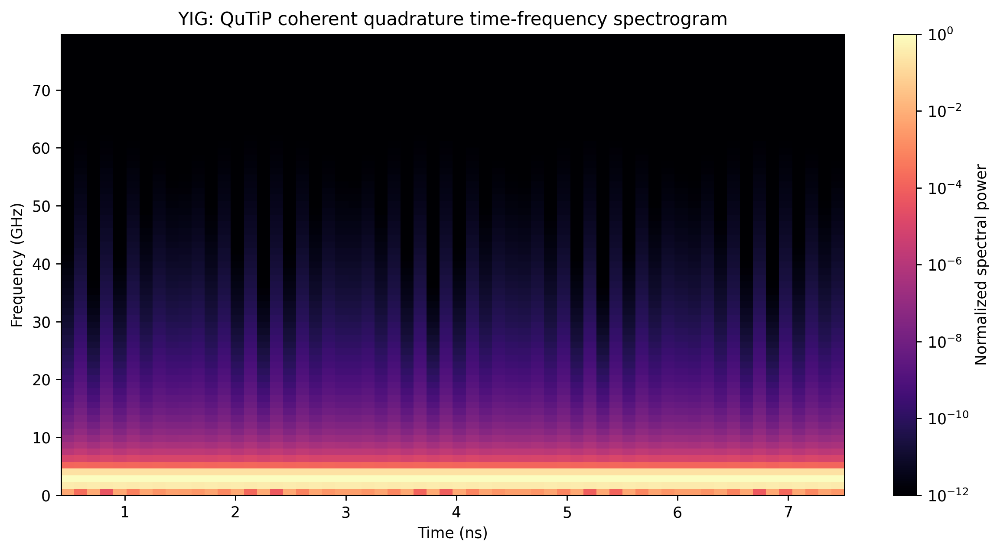

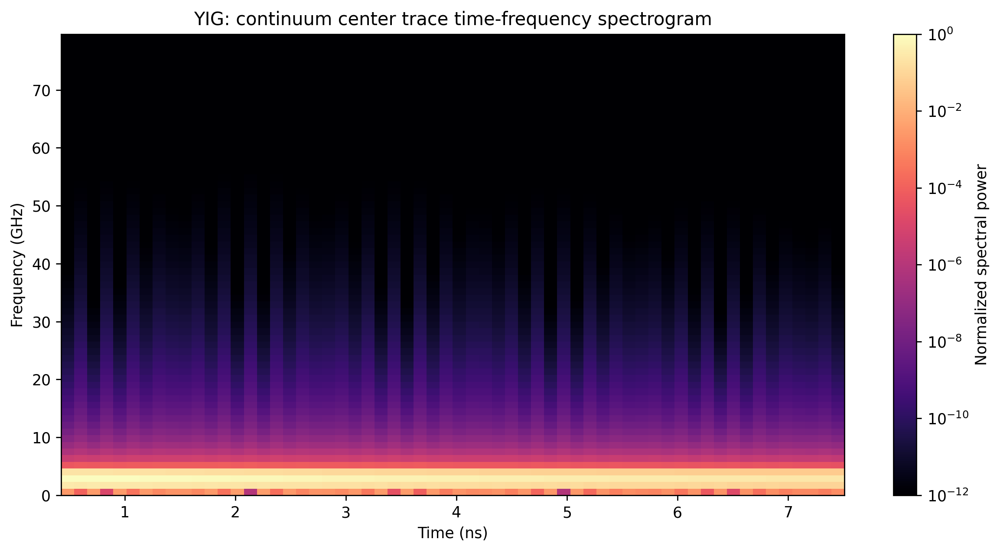

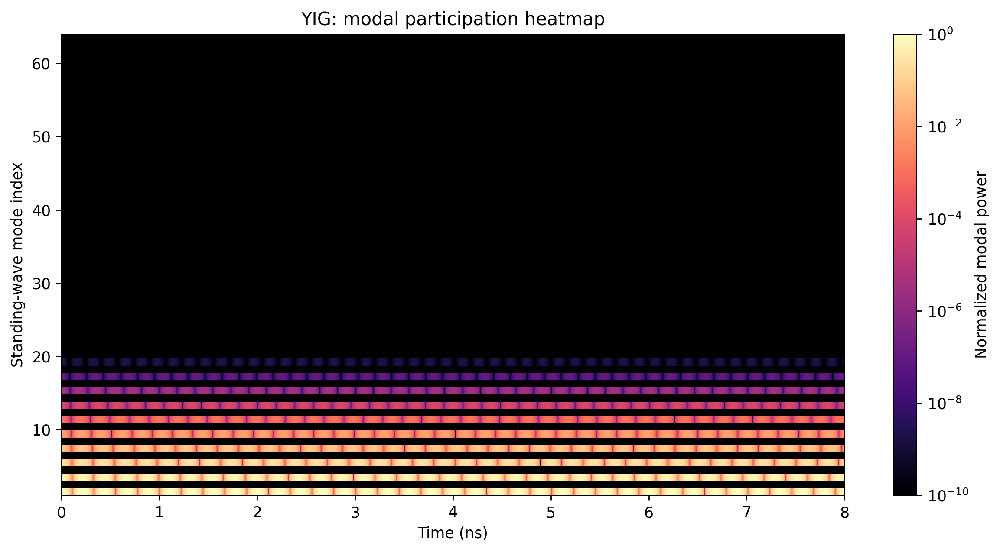

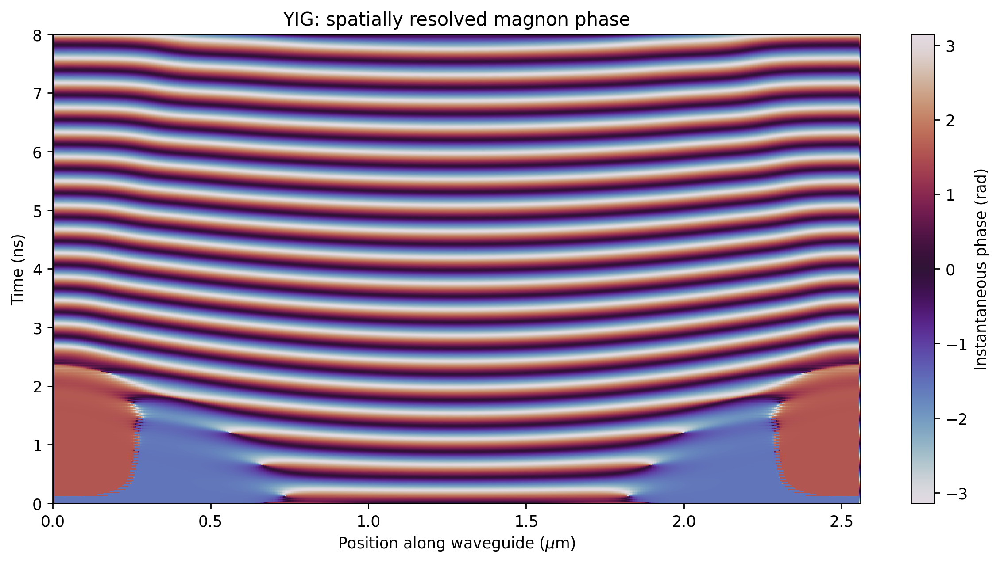

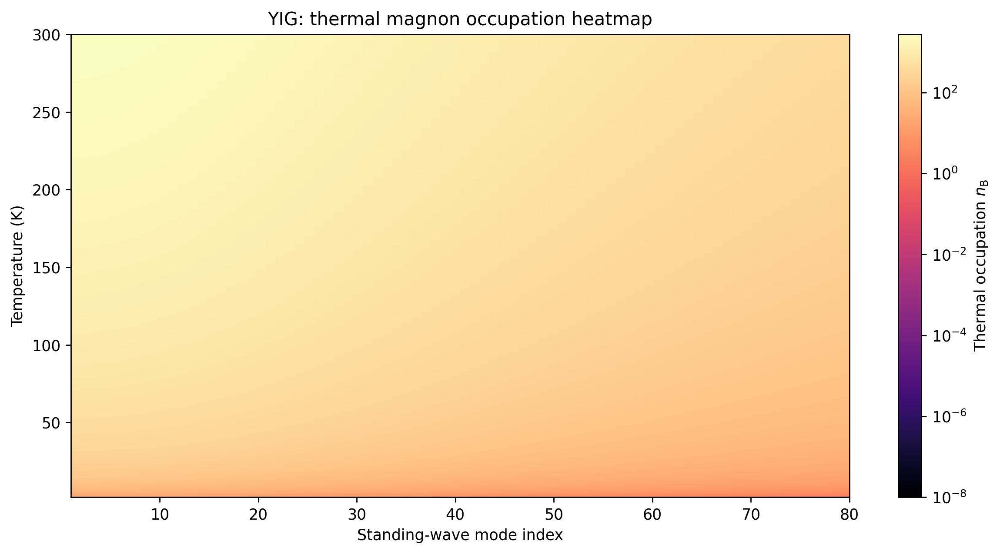

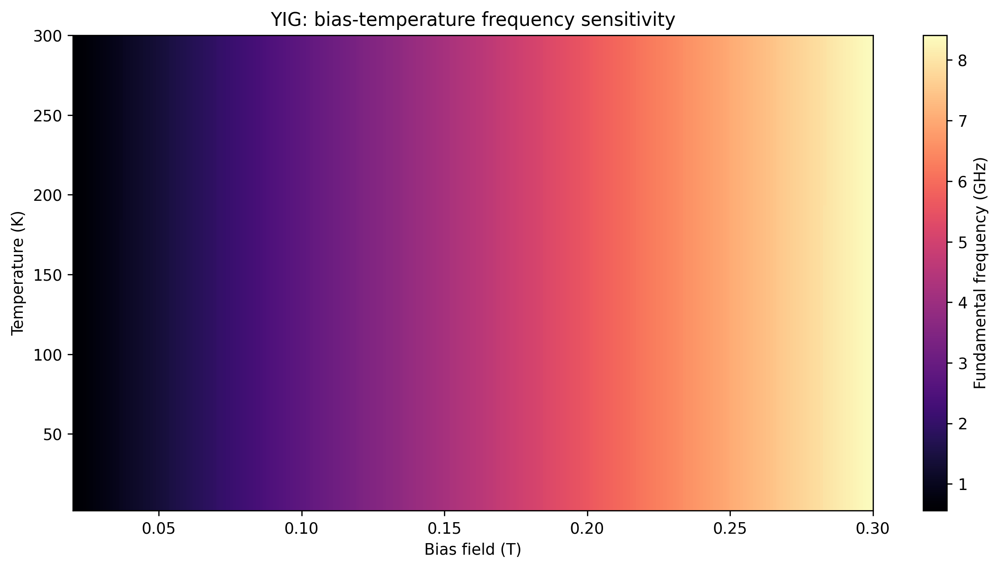


=== Additional heatmaps for CoFeB ===


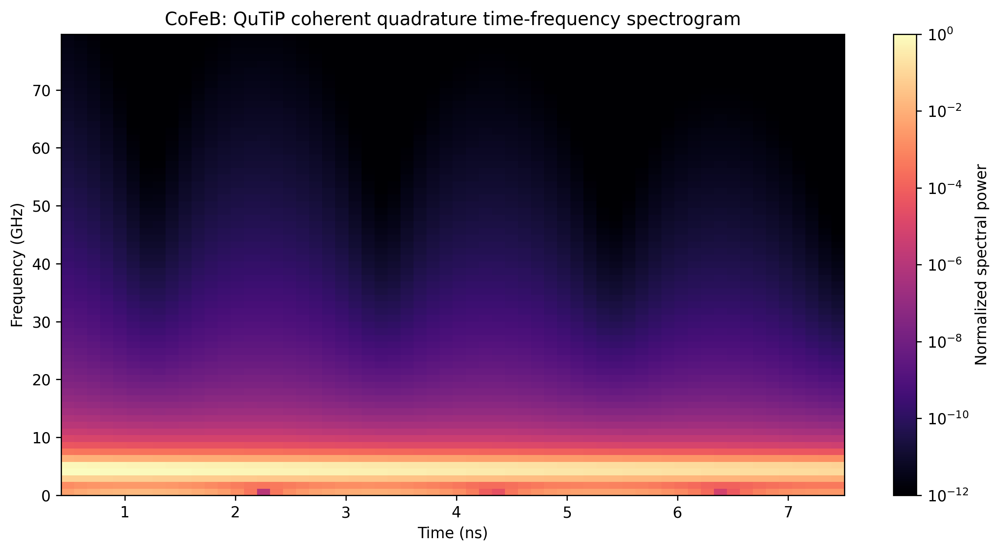

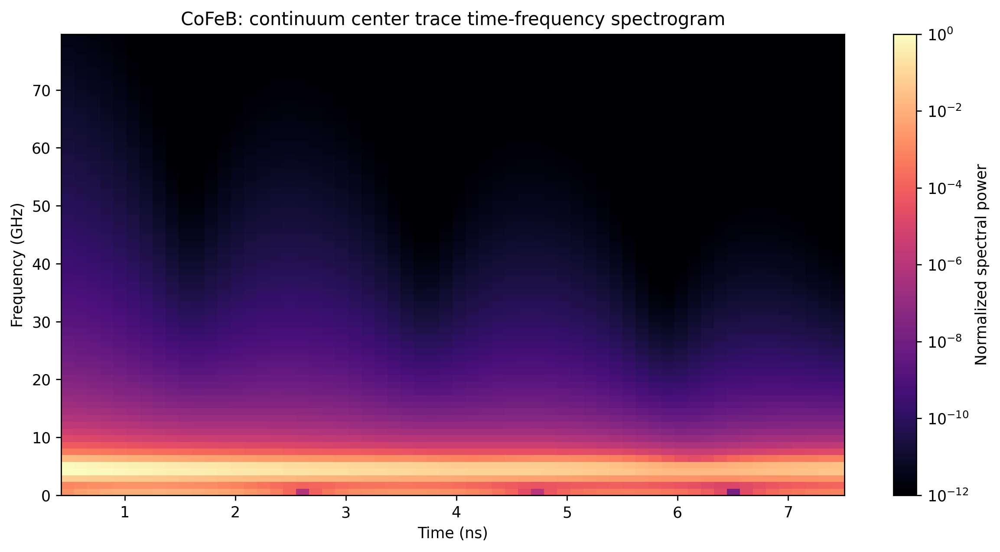

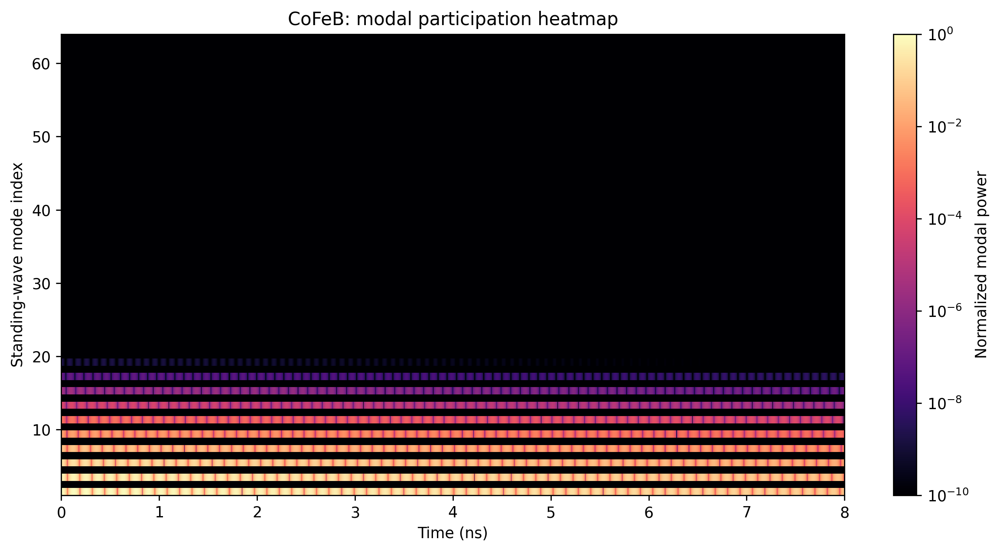

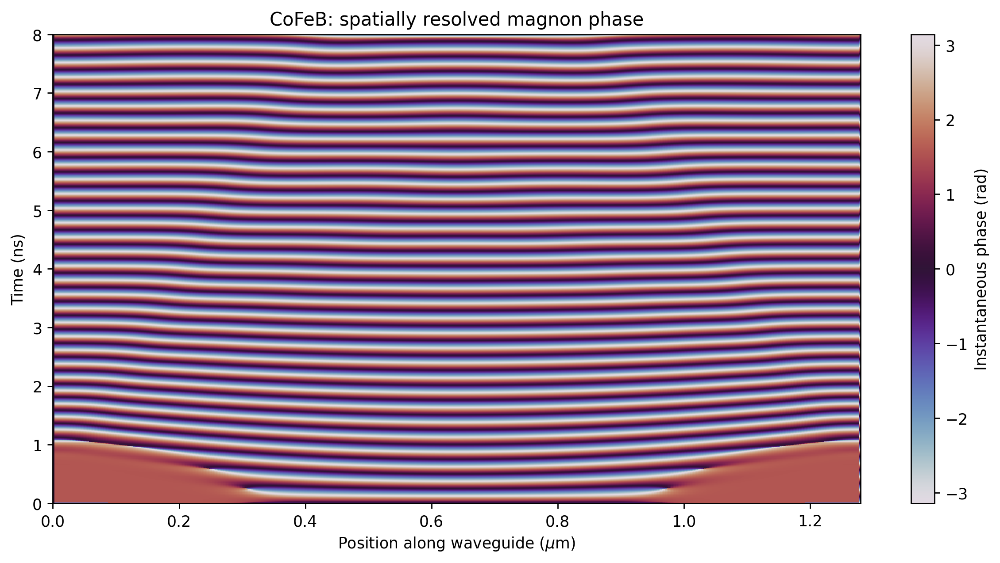

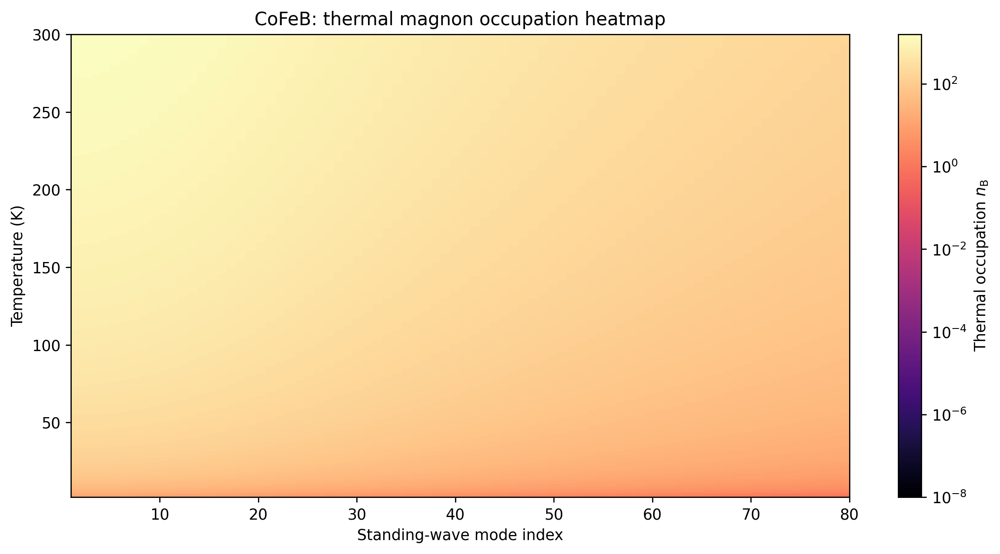

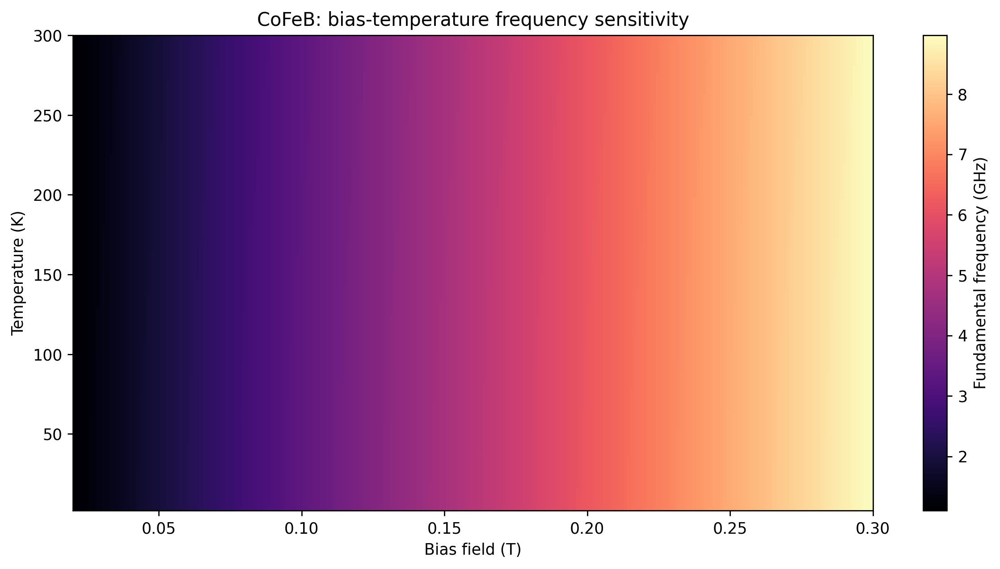

In [6]:
#@title Additional Heatmap Suite for Quantum and Continuum Magnon Diagnostics
"""Additional heatmaps for the Ehrenfest-Weiss magnon workflow.

This cell adds:
1. Time-frequency spectrograms for QuTiP and continuum traces.
2. Standing-wave modal participation heatmaps.
3. Spatially resolved instantaneous phase heatmaps.
4. Thermal Bose occupation heatmaps over temperature and mode index.
5. Bias-field versus temperature frequency sensitivity heatmaps.
"""

import math
from typing import Any, Final

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as signal
from matplotlib.colors import LogNorm


# =============================================================================
# CONTROL KNOBS
# =============================================================================

MPL_DPI: Final[int] = 250

HEATMAP_CMAP: Final[str] = "magma"
PHASE_CMAP: Final[str] = "twilight"

SPECTROGRAM_NPERSEG: Final[int] = 192
SPECTROGRAM_OVERLAP_FRACTION: Final[float] = 0.86
SPECTROGRAM_MAX_GHZ: Final[float] = 80.0
SPECTROGRAM_POWER_FLOOR: Final[float] = 1.0e-12

MODAL_HEATMAP_MODE_COUNT: Final[int] = 64
MODAL_POWER_FLOOR: Final[float] = 1.0e-10

THERMAL_MODE_COUNT: Final[int] = 80
THERMAL_TEMPERATURE_MIN_K: Final[float] = 2.0
THERMAL_TEMPERATURE_MAX_K: Final[float] = 300.0
THERMAL_TEMPERATURE_POINTS: Final[int] = 320
THERMAL_OCCUPATION_FLOOR: Final[float] = 1.0e-8

BIAS_FIELD_MIN_T: Final[float] = 0.02
BIAS_FIELD_MAX_T: Final[float] = 0.30
BIAS_FIELD_POINTS: Final[int] = 240
BIAS_TEMPERATURE_POINTS: Final[int] = 240

TEMPERATURE_EXCHANGE_SCALING_POWER: Final[float] = 2.0

GAMMA_RAD_PER_T_S: Final[float] = 1.760_859_630e11
PLANCK_J_S: Final[float] = 6.626_070_15e-34
BOLTZMANN_J_PER_K: Final[float] = 1.380_649e-23


# =============================================================================
# MATPLOTLIB CONFIGURATION
# =============================================================================

mpl.rcParams["figure.dpi"] = MPL_DPI
mpl.rcParams["savefig.dpi"] = MPL_DPI
mpl.rcParams["font.sans-serif"] = ["Tahoma", "DejaVu Sans"]
mpl.rcParams["axes.grid"] = False


# =============================================================================
# GENERAL HELPERS
# =============================================================================

def get_previous_results() -> list[dict[str, Any]]:
    """Return existing comparison results or execute the previous main function."""
    previous_results = globals().get("results")

    if previous_results is None:
        previous_main = globals().get("main")
        if callable(previous_main):
            print("Executing previous main function because `results` was absent.")
            previous_results = previous_main()
        else:
            raise RuntimeError(
                "Run the main magnon comparison cell before this heatmap cell."
            )

    if len(previous_results) == 0:
        raise RuntimeError("The `results` list is empty.")

    return previous_results


def get_attr(obj: Any, name: str, default: Any = None) -> Any:
    """Read either a dataclass/object attribute or a dictionary entry."""
    if hasattr(obj, name):
        return getattr(obj, name)

    if isinstance(obj, dict):
        return obj.get(name, default)

    return default


def as_float_array(values: Any) -> np.ndarray:
    """Convert array-like values into a finite floating-point NumPy array."""
    try:
        import cupy as cp

        if isinstance(values, cp.ndarray):
            values = cp.asnumpy(values)
    except Exception:
        pass

    array = np.asarray(values, dtype=float)
    return np.nan_to_num(array, nan=0.0, posinf=0.0, neginf=0.0)


def normalize_power(power: np.ndarray, floor: float) -> np.ndarray:
    """Normalize a nonnegative power map and apply a plotting floor."""
    power = np.asarray(power, dtype=float)
    power = np.maximum(power, 0.0)
    scale = max(float(np.max(power)), 1.0e-300)
    return np.maximum(power / scale, floor)


def centered_time_ns(time_s: np.ndarray) -> np.ndarray:
    """Convert time in seconds to zero-based nanoseconds."""
    time_ns = as_float_array(time_s) * 1.0e9
    return time_ns - float(time_ns[0])


def orient_field_xt(x_m: np.ndarray, field_xt: np.ndarray) -> np.ndarray:
    """Ensure continuum field has shape (space, time)."""
    field_xt = as_float_array(field_xt)

    if field_xt.ndim != 2:
        raise ValueError(
            f"Expected a 2D continuum field, received shape {field_xt.shape}."
        )

    if field_xt.shape[0] == x_m.size:
        return field_xt

    if field_xt.shape[1] == x_m.size:
        return field_xt.T

    raise ValueError(
        "The continuum field shape is incompatible with the spatial grid. "
        f"x_m has {x_m.size} points, field shape is {field_xt.shape}."
    )


def trapezoid_weights(x_values: np.ndarray) -> np.ndarray:
    """Return trapezoidal integration weights without np.trapezoid."""
    x_values = as_float_array(x_values)

    if x_values.size < 2:
        raise ValueError("At least two grid points are required.")

    weights = np.zeros_like(x_values, dtype=float)
    weights[0] = 0.5 * (x_values[1] - x_values[0])
    weights[-1] = 0.5 * (x_values[-1] - x_values[-2])

    if x_values.size > 2:
        weights[1:-1] = 0.5 * (x_values[2:] - x_values[:-2])

    return weights


def reduced_magnetization(
    material: Any,
    temperature_k: np.ndarray,
) -> np.ndarray:
    """Compute the finite-temperature normalized magnetization model."""
    curie_temp_k = float(get_attr(material, "curie_temp_k"))
    temp_strength = float(get_attr(material, "temp_strength"))

    theta = np.clip(temperature_k / curie_temp_k, 0.0, 0.999)
    reduced = 1.0 - temp_strength * theta**1.5
    return np.clip(reduced, 1.0e-5, 0.999_999)


def mode_frequency_matrix_hz(
    material: Any,
    mode_count: int,
    temperature_k: np.ndarray,
) -> np.ndarray:
    """Compute frequency matrix with shape (temperature, mode)."""
    msat_0 = float(get_attr(material, "msat_0_a_per_m"))
    aex_0 = float(get_attr(material, "aex_0_j_per_m"))
    length_m = float(get_attr(material, "length_m"))
    bias_field_t = float(get_attr(material, "bias_field_t"))
    anisotropy_field_t = float(get_attr(material, "anisotropy_field_t", 0.0))

    temperature_k = as_float_array(temperature_k)
    reduced = reduced_magnetization(material, temperature_k)[:, None]

    mode_indices = np.arange(1, mode_count + 1, dtype=float)[None, :]
    k_modes = math.pi * mode_indices / length_m

    ms_t = msat_0 * reduced
    aex_t = aex_0 * reduced**TEMPERATURE_EXCHANGE_SCALING_POWER
    exchange_field_t = 2.0 * aex_t * k_modes**2 / ms_t
    total_field_t = bias_field_t + anisotropy_field_t * reduced + exchange_field_t

    return GAMMA_RAD_PER_T_S * total_field_t / (2.0 * math.pi)


def fundamental_frequency_grid_ghz(
    material: Any,
    temperature_k: np.ndarray,
    bias_field_t: np.ndarray,
) -> np.ndarray:
    """Compute fundamental frequency grid with shape (temperature, bias)."""
    msat_0 = float(get_attr(material, "msat_0_a_per_m"))
    aex_0 = float(get_attr(material, "aex_0_j_per_m"))
    length_m = float(get_attr(material, "length_m"))
    anisotropy_field_t = float(get_attr(material, "anisotropy_field_t", 0.0))

    temperature_k = as_float_array(temperature_k)
    bias_field_t = as_float_array(bias_field_t)

    reduced = reduced_magnetization(material, temperature_k)[:, None]
    bias_grid_t = bias_field_t[None, :]

    k_1 = math.pi / length_m
    ms_t = msat_0 * reduced
    aex_t = aex_0 * reduced**TEMPERATURE_EXCHANGE_SCALING_POWER
    exchange_field_t = 2.0 * aex_t * k_1**2 / ms_t

    total_field_t = bias_grid_t + anisotropy_field_t * reduced + exchange_field_t
    frequency_hz = GAMMA_RAD_PER_T_S * total_field_t / (2.0 * math.pi)

    return frequency_hz * 1.0e-9


# =============================================================================
# TIME-FREQUENCY SPECTROGRAMS
# =============================================================================

def compute_spectrogram(
    time_s: np.ndarray,
    trace: np.ndarray,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Compute a normalized spectrogram from a time trace."""
    time_s = as_float_array(time_s)
    trace = signal.detrend(as_float_array(trace), type="constant")

    if trace.size < 8:
        raise ValueError("Trace is too short for a spectrogram.")

    dt_s = float(np.mean(np.diff(time_s)))
    sample_rate_hz = 1.0 / dt_s

    nperseg = min(SPECTROGRAM_NPERSEG, trace.size)
    noverlap = int(SPECTROGRAM_OVERLAP_FRACTION * nperseg)
    noverlap = min(noverlap, nperseg - 1)

    freq_hz, time_local_s, spec_power = signal.spectrogram(
        trace,
        fs=sample_rate_hz,
        window="hann",
        nperseg=nperseg,
        noverlap=noverlap,
        detrend="constant",
        scaling="spectrum",
        mode="psd",
    )

    spec_power = normalize_power(spec_power, SPECTROGRAM_POWER_FLOOR)
    time_ns = (time_local_s + float(time_s[0])) * 1.0e9
    time_ns = time_ns - float(time_s[0]) * 1.0e9

    return freq_hz, time_ns, spec_power


def plot_spectrogram_heatmap(
    material_name: str,
    source_name: str,
    time_s: np.ndarray,
    trace: np.ndarray,
) -> None:
    """Render a time-frequency spectrogram heatmap."""
    freq_hz, time_ns, spec_power = compute_spectrogram(time_s, trace)

    freq_mask = freq_hz <= SPECTROGRAM_MAX_GHZ * 1.0e9
    freq_plot_hz = freq_hz[freq_mask]
    spec_plot = spec_power[freq_mask, :]

    extent = [
        float(time_ns[0]),
        float(time_ns[-1]),
        float(freq_plot_hz[0] * 1.0e-9),
        float(freq_plot_hz[-1] * 1.0e-9),
    ]

    plt.figure(figsize=(9.8, 5.2))
    image = plt.imshow(
        spec_plot,
        origin="lower",
        aspect="auto",
        extent=extent,
        interpolation="nearest",
        cmap=HEATMAP_CMAP,
        norm=LogNorm(
            vmin=SPECTROGRAM_POWER_FLOOR,
            vmax=max(float(np.max(spec_plot)), 10.0 * SPECTROGRAM_POWER_FLOOR),
        ),
    )
    plt.colorbar(image, label="Normalized spectral power")
    plt.xlabel("Time (ns)")
    plt.ylabel("Frequency (GHz)")
    plt.title(f"{material_name}: {source_name} time-frequency spectrogram")
    plt.tight_layout()
    plt.show()


# =============================================================================
# STANDING-WAVE MODAL PARTICIPATION
# =============================================================================

def compute_modal_participation(
    x_m: np.ndarray,
    field_xt: np.ndarray,
    mode_count: int,
) -> tuple[np.ndarray, np.ndarray]:
    """Project a continuum field onto 1D sine standing-wave modes."""
    x_m = as_float_array(x_m)
    field_xt = orient_field_xt(x_m, field_xt)

    length_m = float(x_m[-1] - x_m[0])
    x_shifted = x_m - float(x_m[0])

    mode_indices = np.arange(1, mode_count + 1, dtype=float)
    basis = np.sin(
        math.pi * x_shifted[:, None] * mode_indices[None, :] / length_m
    )

    weights = trapezoid_weights(x_shifted)
    weighted_field = field_xt * weights[:, None]

    coefficients = (2.0 / length_m) * (basis.T @ weighted_field)
    power = normalize_power(coefficients**2, MODAL_POWER_FLOOR)

    return mode_indices, power


def plot_modal_participation_heatmap(result: dict[str, Any]) -> None:
    """Render mode-index versus time modal participation."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))
    continuum = result["continuum"]

    x_m = as_float_array(continuum["x_m"])
    time_ns = centered_time_ns(as_float_array(continuum["time_s"]))
    field_xt = as_float_array(continuum["psi_real"])

    mode_indices, modal_power = compute_modal_participation(
        x_m,
        field_xt,
        MODAL_HEATMAP_MODE_COUNT,
    )

    extent = [
        float(time_ns[0]),
        float(time_ns[-1]),
        float(mode_indices[0]),
        float(mode_indices[-1]),
    ]

    plt.figure(figsize=(9.8, 5.2))
    image = plt.imshow(
        modal_power,
        origin="lower",
        aspect="auto",
        extent=extent,
        interpolation="nearest",
        cmap=HEATMAP_CMAP,
        norm=LogNorm(
            vmin=MODAL_POWER_FLOOR,
            vmax=max(float(np.max(modal_power)), 10.0 * MODAL_POWER_FLOOR),
        ),
    )
    plt.colorbar(image, label="Normalized modal power")
    plt.xlabel("Time (ns)")
    plt.ylabel("Standing-wave mode index")
    plt.title(f"{material_name}: modal participation heatmap")
    plt.tight_layout()
    plt.show()


# =============================================================================
# SPATIALLY RESOLVED PHASE
# =============================================================================

def plot_phase_heatmap(result: dict[str, Any]) -> None:
    """Render the instantaneous phase map of the continuum field."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))
    continuum = result["continuum"]

    x_um = as_float_array(continuum["x_m"]) * 1.0e6
    time_ns = centered_time_ns(as_float_array(continuum["time_s"]))
    field_xt = orient_field_xt(
        as_float_array(continuum["x_m"]),
        as_float_array(continuum["psi_real"]),
    )

    analytic_field = signal.hilbert(field_xt, axis=1)
    phase = np.angle(analytic_field)

    extent = [
        float(x_um[0]),
        float(x_um[-1]),
        float(time_ns[0]),
        float(time_ns[-1]),
    ]

    plt.figure(figsize=(9.8, 5.2))
    image = plt.imshow(
        phase.T,
        origin="lower",
        aspect="auto",
        extent=extent,
        interpolation="nearest",
        cmap=PHASE_CMAP,
        vmin=-math.pi,
        vmax=math.pi,
    )
    plt.colorbar(image, label="Instantaneous phase (rad)")
    plt.xlabel(r"Position along waveguide ($\mu$m)")
    plt.ylabel("Time (ns)")
    plt.title(f"{material_name}: spatially resolved magnon phase")
    plt.tight_layout()
    plt.show()


# =============================================================================
# THERMAL OCCUPATION HEATMAP
# =============================================================================

def bose_occupation(freq_hz: np.ndarray, temperature_k: np.ndarray) -> np.ndarray:
    """Compute Bose-Einstein thermal magnon occupation."""
    freq_hz = np.asarray(freq_hz, dtype=float)
    temperature_k = np.asarray(temperature_k, dtype=float)

    energy_j = PLANCK_J_S * np.maximum(freq_hz, 1.0e-30)
    thermal_j = BOLTZMANN_J_PER_K * np.maximum(temperature_k, 1.0e-12)

    exponent = energy_j / thermal_j
    exponent = np.clip(exponent, 1.0e-12, 700.0)

    return 1.0 / np.expm1(exponent)


def plot_thermal_occupation_heatmap(result: dict[str, Any]) -> None:
    """Render thermal magnon occupation over temperature and mode index."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))

    temperature_k = np.linspace(
        THERMAL_TEMPERATURE_MIN_K,
        THERMAL_TEMPERATURE_MAX_K,
        THERMAL_TEMPERATURE_POINTS,
    )
    mode_indices = np.arange(1, THERMAL_MODE_COUNT + 1)

    freq_matrix_hz = mode_frequency_matrix_hz(
        material,
        mode_count=THERMAL_MODE_COUNT,
        temperature_k=temperature_k,
    )
    occupation = bose_occupation(freq_matrix_hz, temperature_k[:, None])
    occupation = np.maximum(occupation, THERMAL_OCCUPATION_FLOOR)

    extent = [
        float(mode_indices[0]),
        float(mode_indices[-1]),
        float(temperature_k[0]),
        float(temperature_k[-1]),
    ]

    plt.figure(figsize=(9.8, 5.2))
    image = plt.imshow(
        occupation,
        origin="lower",
        aspect="auto",
        extent=extent,
        interpolation="nearest",
        cmap=HEATMAP_CMAP,
        norm=LogNorm(
            vmin=THERMAL_OCCUPATION_FLOOR,
            vmax=max(float(np.max(occupation)), 10.0 * THERMAL_OCCUPATION_FLOOR),
        ),
    )
    plt.colorbar(image, label=r"Thermal occupation $n_\mathrm{B}$")
    plt.xlabel("Standing-wave mode index")
    plt.ylabel("Temperature (K)")
    plt.title(f"{material_name}: thermal magnon occupation heatmap")
    plt.tight_layout()
    plt.show()


# =============================================================================
# BIAS-FIELD VERSUS TEMPERATURE SENSITIVITY
# =============================================================================

def plot_bias_temperature_frequency_heatmap(result: dict[str, Any]) -> None:
    """Render fundamental frequency versus bias field and temperature."""
    material = result["material"]
    material_name = str(get_attr(material, "name", "material"))

    temperature_k = np.linspace(
        THERMAL_TEMPERATURE_MIN_K,
        THERMAL_TEMPERATURE_MAX_K,
        BIAS_TEMPERATURE_POINTS,
    )
    bias_field_t = np.linspace(
        BIAS_FIELD_MIN_T,
        BIAS_FIELD_MAX_T,
        BIAS_FIELD_POINTS,
    )

    frequency_ghz = fundamental_frequency_grid_ghz(
        material,
        temperature_k=temperature_k,
        bias_field_t=bias_field_t,
    )

    extent = [
        float(bias_field_t[0]),
        float(bias_field_t[-1]),
        float(temperature_k[0]),
        float(temperature_k[-1]),
    ]

    plt.figure(figsize=(9.8, 5.2))
    image = plt.imshow(
        frequency_ghz,
        origin="lower",
        aspect="auto",
        extent=extent,
        interpolation="nearest",
        cmap=HEATMAP_CMAP,
    )
    plt.colorbar(image, label="Fundamental frequency (GHz)")
    plt.xlabel("Bias field (T)")
    plt.ylabel("Temperature (K)")
    plt.title(f"{material_name}: bias-temperature frequency sensitivity")
    plt.tight_layout()
    plt.show()


# =============================================================================
# DRIVER
# =============================================================================

def run_additional_heatmap_suite() -> dict[str, Any]:
    """Render all additional heatmap diagnostics."""
    previous_results = get_previous_results()

    print("Running additional heatmap diagnostics.")
    print(f"Number of material cases: {len(previous_results)}")

    for result in previous_results:
        material = result["material"]
        material_name = str(get_attr(material, "name", "material"))
        quantum = result["quantum"]
        continuum = result["continuum"]

        print(f"\n=== Additional heatmaps for {material_name} ===")

        plot_spectrogram_heatmap(
            material_name=material_name,
            source_name="QuTiP coherent quadrature",
            time_s=as_float_array(quantum["time_s"]),
            trace=as_float_array(quantum["coherent_x"]),
        )
        plot_spectrogram_heatmap(
            material_name=material_name,
            source_name="continuum center trace",
            time_s=as_float_array(continuum["time_s"]),
            trace=as_float_array(continuum["center_trace"]),
        )
        plot_modal_participation_heatmap(result)
        plot_phase_heatmap(result)
        plot_thermal_occupation_heatmap(result)
        plot_bias_temperature_frequency_heatmap(result)

    return {
        "status": "completed",
        "material_count": len(previous_results),
    }


if __name__ == "__main__":
    additional_heatmaps = run_additional_heatmap_suite()